# Kyara: Knowledge Yielding Adaptive Retrieval Augmentation for LLM Fine-tuning

<p align="left">
    🤗 <a href="https://huggingface.co/zake7749/gemma-2-2b-it-chinese-kyara-dpo">Hugging Face</a>&nbsp; ｜ 🚀<a href="https://github.com/zake7749/kyara">Github</a>&nbsp; ｜ &nbsp;📑 <a href="#">Paper</a>&nbsp; ｜ &nbsp;📖 <a href="https://github.com/zake7749/kyara/blob/main/document/README_EN.md">English</a>&nbsp; ｜ &nbsp;📖 <a href="https://github.com/zake7749/kyara">Chinese</a>&nbsp; ｜ &nbsp;💻 <a href="https://www.kaggle.com/code/zake7749/kyara-a-compact-yet-powerful-chinese-llm">Kaggle Notebook</a>
</p>

<div style="text-align: center;">
  <img src="https://i.imgur.com/QiWlcYJ.jpeg" alt="kyara"/>
</div>

---

Kyara (Knowledge Yielding Adaptive Retrieval Augmentation) is an experimental project aimed at improving language models through knowledge retrieval processes. The project seeks to enhance the model’s ability to adapt knowledge and improve language comprehension, particularly in underrepresented languages like Traditional Chinese. Given the relatively scarce availability of Traditional Chinese data compared to the vast corpus of English data used for model training, Kyara addresses this gap by expanding the limited corpus for this language.

To validate Kyara's effectiveness, we conducted full-parameter fine-tuning on `Gemma-2` models, resulting in the first iteration of the Kyara model. Initial evaluation results on the [Benchmark](https://github.com/zake7749/Kyara/blob/main/document/README_EN.md), demonstrate that Kyara outperforms the original `Gemma-2` series across various benchmarks, with notable improvements in Chinese language evaluations:

#### General Knowledge Benchmark

##### Chinese Evaluation

| Metric                   | Kyara-1.5-2b-it    | Gemma-2-2b-it |  Kyara-2.5-9b-it   |  Gemma-2-9b-it     |
|--------------------------|--------------------|---------------|--------------------|--------------------|
| **[TMMLUPlus](https://huggingface.co/datasets/ikala/tmmluplus)**   | **42.57**     | 36.90      | **59.87**   | 54.77      |
| &emsp;- STEM                                                       | **45.24**     | 37.45      | **66.98**   | 58.12      | 
| &emsp;- Humanities                                                 | **38.94**     | 33.63      | **54.42**   | 48.71      |
| &emsp;- Other                                                      | **41.16**     | 36.09      | **55.26**   | 51.43      |
| &emsp;- Social-Science                                             | **44.95**     | 40.43      | **62.81**   | 60.84      |
| **[MMLU-Redux](https://github.com/yuchenlin/ZeroEval)**            | **55.44**     | 51.94      | 72.57       | **72.82**  |
| **[GSM8K](https://github.com/yuchenlin/ZeroEval)**                 | **54.21**     | 51.63      | **90.60**   | 87.41      |
| **[MATH-L5](https://github.com/yuchenlin/ZeroEval)**               | **8.88**      |  4.3       | **28.71**   | 19.42      |
| **[CRUX](https://github.com/yuchenlin/ZeroEval)**                  | **22.75**     | 21.5       | **48.62**   | 46.00      |
| **[ZebraLogic](https://github.com/yuchenlin/ZeroEval)**            | **5.2**       |  4.2       | **16.8**    | 12.8       |

#### Automatic Evaluation Benchmark

| Metric                   | Kyara-1.5-2b-it    | Gemma-2-2b-it | ChatGPT-3.5-1106 |  Kyara-2.5-9b-it   |  Gemma-2-9b-it  |       
|--------------------------|--------------------|---------------|------------------|--------------------|--------------------|
| **[AlpacaEval-LC](https://github.com/tatsu-lab/alpaca_eval)**                   | **35.35** | 32.37       | 19.30    | -        |   -    |
| **[AlpacaEval](https://github.com/tatsu-lab/alpaca_eval)**                      | **43.34** | 32.94       | 9.20     | -        |   -    |
| **[Chatbot-Arena-Hard](https://github.com/lm-sys/arena-hard-auto)**             | **22.60** | 19.4        | 18.87    | **41.1** |  33.6  |
| **[MT-Bench-TW](https://huggingface.co/datasets/MediaTek-Research/TCEval-v2)**  | **7.43**  | 6.35        | 7.10     | **8.36** |  7.80  |
| **[MT-Bench](https://huggingface.co/spaces/lmsys/mt-bench)**                    | 8.28      | 8.17        | 8.32     | **8.81** |  8.53  |

This notebook is designed for beginners in Machine Learning and Natural Language Processing. Instead of delving deeply into the mathematical details, we will focus on the insights and motivations behind why and how we approach certain tasks. For those who wish to explore the technical details further, we’ll provide references and relevant research papers.

By the end of this notebook, we hope you'll gain a clear understanding of the process involved in preparing data, training, evaluating, and inferring with large language models. Let’s start by diving into the data aspect.

---

# Data Construction

In this chapter, we would introduce how to construct datasets for supervised fine-tuning (SFT) and preference optimization (PO). Additionally, we would present two small-scale Traditional Chinese datasets for SFT and PO training, respectively. Most of the data used in Kyara is synthesized using large language models (LLMs). For the purpose of this tutorial, we will use the kyara-1.5-2b model for efficiency. However, you can replace it with more powerful LLMs for real-world applications. Below is a simple chat interface for the Kyara model.

In [1]:
!pip install -U transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 75.5 MB/s eta 0:00:00
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.19.1
    Uninstalling tokenizers-0.19.1:
      Successfully uninstalled tokenizers-0.19.1
  Attempting uninstall: transformers
    Found existing installation: transformers 4.44.2
    Uninstalling transformers-4.44.2:
      Successfully uninstalled transformers-4.44.2


In [2]:
import torch
from transformers import pipeline

class KyaraChatter:
    
    def __init__(self, model_path: str, device: torch.device = None):
        # Recommend using the P100 as the accelerator.
        self.device = device or torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        self.dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        self.pipe = pipeline("text-generation", 
                             model=model_path, device=self.device, 
                             torch_dtype=self.dtype)
        
    def chat_messages(self, messages, *args, **kwargs):
        return self.pipe(messages, *args, **kwargs)
        
    def single_chat(self, prompt, temperature=0.5, max_length=8192, *args, **kwargs):
        messages = [{"role": "user", "content": prompt}]
        response = self.chat_messages(
            messages, 
            temperature=temperature,
            max_length=max_length,
            *args, **kwargs
        )[0]['generated_text'][-1]['content']
        return response
        
model_path = "/kaggle/input/gemma-2-2b-it-chinese-kyara-dpo/transformers/zh-v1.5/1"
chatter = KyaraChatter(model_path)

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Device set to use cuda:0


## Supervised Fine-Tuning

Let's begin with supervised fine-tuning. There are three main methods for constructing the Kyara dataset:

1. **Retrieve, Rewrite, and Reformulate:** Build comprehensive QA pairs with a RAG graph.
2. **Translation and Rewriting:** Utilize well-constructed open-source datasets by translating and rephrasing SFT pairs.  
3. **Generating QA Pairs from Original Documents:** Transform raw documents into QA pairs and generate prompts for real-world use cases.  

We would also randomly apply various techniques, such as introducing personas, on the above methods to increase the data diversity.

Lastly, we would provide an overview of multi-turn dialogue generation and discuss approaches to managing dataset quality.

### Retrieve, Rewrite, and Reformulate

The primary goal of Kyara is to connect the dots in knowledge acquisition. To illustrate this, consider how we learn a new concept, such as a Markov Chain. When encountering the definition of a Markov Chain, we often need to reference related concepts, such as Markov Processes and Stochastic Matrices. As we explore these topics, we may find ourselves diving into additional documents to fill gaps in our understanding, repeating this process until we feel we have gathered sufficient information—or until fatigue sets in.

This learning process can be reformulated in terms of graph theory. Imagine each Wikipedia page as a node in a graph, with hyperlinks representing directed edges that connect one page to another. Learning, in this sense, is equivalent to traversing this graph: connecting isolated nodes into a coherent knowledge path or even a comprehensive knowledge graph. This idea aligns with the principles of connectivism in learning theory, which posits that understanding a concept is often facilitated by exploring its neighbors within a broader network of related knowledge.

Kyara leverages this graph-based perspective to construct Q&A datasets that mirror the natural process of learning. By systematically retrieving, rewriting, and reformulating content from interconnected nodes, Kyara builds question-answer pairs that capture both the depth of individual concepts and the relationships between them. The overview of Kyara's workflow is illustrated in the following figure:

<div style="text-align: center;">
  <img src="https://i.imgur.com/bNfAgrd.png" alt="r3-process"/>
</div>

In the subsequent sections, we will discuss the details of each component, starting with the retrieval process.

#### Retrieval Process

The primary goal of the retrieval process is to gather sufficient relevant information to address the user's query. However, before retrieval can begin, we must first build a query pool.

##### Query Generation

We conduct query generation using a variety of prompt templates to enhance task diversity and complexity. Despite this variation, the core principle remains the same: Reason first, then Generate. For instance, consider the topic [Wave–Particle Duality](https://zh.wikipedia.org/zh-tw/%E6%B3%A2%E7%B2%92%E4%BA%8C%E8%B1%A1%E6%80%A7):

In [3]:
article = """# 波粒二象性

波粒二象性（英語：Wave–Particle Duality）指的是以古典力學的觀點來看待非相對論量子力學所描述的微觀粒子的話，微觀粒子會同時顯示出古典上的波動性與粒子性。比如說，古典力學把波函數的位置觀測結果必為明確位置視為「粒子性」；一方面又把機率幅具有的線性疊加性視為「波動性」。

### 理論概述

古典力學的研究對象總是被明確區分為「純」粒子和「純」波動。前者組成了我們常說的「物質」，後者的典型例子則是光波。但(不含狹義相對論的)量子力學認為自然界的基本粒子，如光子、電子或是質子，都能用薛丁格方程式來描述。這個方程式的解即為波函數，其絕對值平方表示粒子在某一處被發現的機率密度。更一般的來說，波函數是可以直觀視為觀測到粒子為特定位置的機率幅，機率幅具有疊加性，它們就像波，描述不同途徑的機率幅可以用疊加的方式互相干涉。

日常生活中觀察不到物體的「波動性」，是因為他們皆質量太大，導致德布羅意波長比可觀察的極限尺寸要小很多，因此可能發生波動性質的尺寸在日常生活經驗範圍之外。這也是為什麼古典力學能夠令人滿意地解釋「自然現象」。反之，對於基本粒子來說，它們的質量和尺寸局限於量子力學所描述的範圍之內，因而與我們所習慣的圖景相差甚遠。"""

We can construct a basic prompt template for query generation as follows:

In [4]:
QG_TEMPLATE = """
{ARTICLE}

---

請你閱讀上述文章，並生成 {NUM} 個使用者可能詢問的問題，以如下 JSON 格式輸出:

```json
{{"queries": List[str]}}
```
"""

# EN-Prompt:
# """
# {ARTICLE}

# ---

# Please refer to the given articl, and generate {NUM} questions user may ask. 
# Output the result with the following JSON format:

# ```json
# {{"queries": List[str]}}
# ```
# """

print(chatter.single_chat(QG_TEMPLATE.format(ARTICLE=article, NUM=3)))

# ```json
# {
#   "queries": [
#     "什麼是波粒二象性？它如何解釋微觀粒子的行為？",
#     "古典力學和量子力學對波動性和粒子的區分有何不同？",
#     "為什麼在日常生活中我們看不到物質的波動性，但在微觀世界中卻如此明顯？"
#   ]
# }
# ```

The 'batch_size' attribute of HybridCache is deprecated and will be removed in v4.49. Use the more precisely named 'self.max_batch_size' attribute instead.


```json
{
  "queries": [
    "波粒二象性是如何在實驗中被證實的？",
    "波函數的絕對值平方在量子力學中代表什麼？",
    "為什麼在微觀尺度上，粒子顯示出波動性，但在宏觀尺度上不顯現波動性？"
  ]
}
```


The resulting queries generated by Kyara can be translated as:

```json
{
  "queries": [
    "What is wave-particle duality? How does it explain the behavior of microscopic particles?",
    "How do classical mechanics and quantum mechanics differ in their distinction between waves and particles?",
    "Why do we not observe the wave-like nature of matter in everyday life, but it becomes so apparent in the microscopic world?"
  ]
}
```

While this is a good starting point, we can refine it further by incorporating step-by-step guidance to enhance the quality and relevance of the queries.

In [5]:
QG_TEMPLATE = """
{ARTICLE}

---

# Task

你是一位好奇心旺盛的學生，閱讀完上述教材後，請從以下幾方面進行回應：

1. 想法與聯想 (Thought)
請簡述這篇文章引發了你哪些想法或聯想？有哪些內容讓你特別感興趣或產生共鳴？

2. 詢問問題 (Queries)
列出你思考後感到困惑的問題，數量為 {NUM} 個。這些問題能推動更深入的學習與探索。

# Output Schema

請先輸出 thought (str), 再輸出想進一步詢問的 {NUM} 個問題以如下 JSON 格式輸出：

```json
{{"thought": str, "queries": List[str]}}
```
"""

# EN-Prompt:
# {ARTICLE}

# ---

# # Task

# You are a curious student. After reading the above material, please respond from the following perspectives:

# 1. Thoughts and Associations (Thought)
# Briefly describe the thoughts or associations this article triggered for you. Which parts of the content particularly interested you or resonated with you?

# 2. Asking Questions (Queries)
# List {NUM} questions that you find confusing or thought-provoking after reflection. These questions should aim to promote deeper learning and exploration.

# # Output Schema

# Please first output the "thought" (str), and then output the {NUM} questions you would like to ask in the following JSON format:

# ```json
# {{"thought": str, "queries": List[str]}}

print(chatter.single_chat(QG_TEMPLATE.format(ARTICLE=article, NUM=3)))
# Output
# ```json
# {
#   "thought": "波粒二象性讓我想到微觀世界的複雜性以及我們如何用古典物理學的框架來理解這些現象。這讓我對量子力學如何挑戰我們對現實的直觀理解產生了濃厚的興趣。特別是波函數的機率幅和疊加性，這些概念似乎與我們日常生活中經驗到的物理現象大相徑庭。這讓我思考，如果我們能用量子力學的視角來觀察宇宙，那會是什麼樣的樣子？",
#   "queries": [
#     "在量子力學中，波函數的疊加原理是如何影響我們對粒子行為的預測的？例如，在雙縫實驗中，粒子的波動性和粒子性是如何同時展現的？",
#     "為什麼在宏觀世界中，我們無法觀察到明顯的波動性，但在微觀世界中卻能觀察到？這是否意味著，隨著物體質量的增加，波動性會減弱，甚至消失？",
#     "波粒二象性是否意味著我們對物理現象的理解需要重新定義？例如，在經典物理中，我們如何將粒子和波的特性分開來看待，而在量子力學中，它們似乎是共存的？"
#   ]
# }
# ```

```json
{
  "thought": "波粒二象性讓我深感驚訝，因為這揭示了微觀世界與我們日常經驗截然不同的特性。特別是，光子既可以被視為粒子，又可以表現出波動性，這挑戰了我們對物質和能量本質的傳統理解。這種二象性讓我想到了量子力學的隨機性與不確定性，這些概念在宏觀世界中似乎不太能被觀察到，卻在微觀層面非常重要。此外，德布羅意波長的概念也引發了我對波動與粒子之間界限的思考，這讓我對量子物理的奇妙性有了更深的興趣。",
  "queries": [
    "在波粒二象性中，如何確定粒子的具體位置？這是否意味著在量子層面上，我們只能預測粒子的概率分佈？",
    "為什麼在宏觀物體中，波動性並不明顯，但在基本粒子中卻如此明顯？這是否與物體的質量有關？",
    "波粒二象性是否意味著我們需要重新定義「粒子」和「波」的傳統概念？如果可以，這是如何影響我們對物理學基本理論的理解的？"
  ]
}
```


The translation of new response would be:

```json
{
  "thought": "The wave-particle duality made me think about the complexity of the microscopic world and how we use classical physics frameworks to understand these phenomena. It sparked a deep interest in how quantum mechanics challenges our intuitive understanding of reality. Concepts like the probability amplitude of the wave function and superposition seem vastly different from the physical phenomena we experience in daily life. This makes me wonder what the universe would look like if we could observe it from the perspective of quantum mechanics.",
  "queries": [
    "How does the principle of superposition in quantum mechanics affect our predictions of particle behavior? For instance, how are the wave-like and particle-like behaviors simultaneously exhibited in the double-slit experiment?",
    "Why can't we observe prominent wave-like behaviors in the macroscopic world, but they are observable in the microscopic world? Does this imply that as an object's mass increases, its wave-like properties diminish or even disappear?",
    "Does wave-particle duality imply that our understanding of physical phenomena needs to be redefined? For example, in classical physics, we separate particle and wave properties, but in quantum mechanics, they seem to coexist."
  ]
}
```

Compared to the earlier queries, the current results are more insightful, detailed, and focused on a coherent thought process. This improvement is attributed to providing clear instructions and adopting a step-by-step generation method.  

At this stage, we can integrate **machine reading comprehension (MRC)** to construct Q&A pairs for supervised fine-tuning (SFT). For instance:  

- **Question**: *How does the principle of superposition in quantum mechanics affect our predictions of particle behavior?*  
- **Answer**: *The principle of superposition allows particles to exist in multiple states simultaneously, which fundamentally affects our predictions. For example, in the double-slit experiment, particles demonstrate both wave-like and particle-like behaviors, depending on the measurement context.*  

By leveraging MRC, we can systematically extract answers to these thoughtful queries, ensuring that the resulting Q&A pairs not only capture factual knowledge but also promote a deeper understanding of the concepts.

In [6]:
mrc_prompt = """# 波粒二象性

波粒二象性（英語：Wave–Particle Duality）指的是以古典力學的觀點來看待非相對論量子力學所描述的微觀粒子的話，微觀粒子會同時顯示出古典上的波動性與粒子性。比如說，古典力學把波函數的位置觀測結果必為明確位置視為「粒子性」；一方面又把機率幅具有的線性疊加性視為「波動性」。

### 理論概述

古典力學的研究對象總是被明確區分為「純」粒子和「純」波動。前者組成了我們常說的「物質」，後者的典型例子則是光波。但(不含狹義相對論的)量子力學認為自然界的基本粒子，如光子、電子或是質子，都能用薛丁格方程式來描述。這個方程式的解即為波函數，其絕對值平方表示粒子在某一處被發現的機率密度。更一般的來說，波函數是可以直觀視為觀測到粒子為特定位置的機率幅，機率幅具有疊加性，它們就像波，描述不同途徑的機率幅可以用疊加的方式互相干涉。

日常生活中觀察不到物體的「波動性」，是因為他們皆質量太大，導致德布羅意波長比可觀察的極限尺寸要小很多，因此可能發生波動性質的尺寸在日常生活經驗範圍之外。這也是為什麼古典力學能夠令人滿意地解釋「自然現象」。反之，對於基本粒子來說，它們的質量和尺寸局限於量子力學所描述的範圍之內，因而與我們所習慣的圖景相差甚遠。

---

請根據上述文章，盡可能回覆以下用戶問題：

在量子力學中，波函數的疊加原理是如何影響我們對粒子行為的預測的？例如，在雙縫實驗中，粒子的波動性和粒子性是如何同時展現的？"""
print(chatter.single_chat(mrc_prompt))

# Output:
# 在量子力學中，波函數的疊加原理是理解粒子行為的重要概念。根據這一原理，當多個波函數（例如，對應於不同位置的粒子）同時存在時，它們可以以數學上的線性組合的形式疊加在一起，形成一個新的波函數。這意味著，對於一個粒子，它的狀態並不僅僅是單一的確定狀態，而是所有可能狀態的「概率幅」的總和。

# 以雙縫實驗為例，這個實驗展示了波粒二象性。當單個粒子（如電子或光子）通過兩個狹縫時，根據波動性的觀點，每個粒子都可以被視為產生波的源頭，這些波在空間中互相干涉，形成干涉圖樣。在觀察粒子通過哪一個縫之前，這些波的疊加使得粒子表現出波動性，產生了干涉條紋。

# 然而，當我們實際觀察到粒子通過哪一個縫時，波函數的疊加被「塌縮」，粒子則顯示出明確的粒子性。這意味著，觀察行為改變了粒子的狀態，從而使其行為不再是波動性的，而是顯示出與古典粒子觀念相符的結果。

# 因此，雙縫實驗不僅展示了粒子的波動性，還顯示了其粒子性，因為在觀察之前，粒子先以波的形式存在，而在觀察後，則以明確的粒子形式出現。這種波粒二象性是量子力學的核心特徵之一，並且挑戰了我們對物質本質的傳統理解。

# Output Translation (from GPT-4o):

# In quantum mechanics, the principle of superposition of wavefunctions is a crucial concept for understanding particle behavior. According to this principle, when multiple wavefunctions (e.g., those corresponding to particles at different positions) coexist, they can be combined mathematically in the form of a linear superposition to create a new wavefunction. This implies that the state of a particle is not a single, definite state but rather the sum of the "probability amplitudes" of all possible states.

# Taking the double-slit experiment as an example, this experiment demonstrates the wave-particle duality. When a single particle (such as an electron or photon) passes through two slits, it can be considered, from the perspective of wave-like behavior, as the source of waves. These waves interfere with each other in space, forming an interference pattern. Before observing which slit the particle passes through, the superposition of these waves causes the particle to exhibit wave-like behavior, producing interference fringes.

# However, when we actually observe which slit the particle passes through, the superposition of the wavefunction "collapses," and the particle displays a distinct particle-like nature. This means that the act of observation alters the particle's state, causing its behavior to no longer be wave-like but instead align with classical particle concepts.

# Thus, the double-slit experiment not only reveals the wave-like nature of particles but also demonstrates their particle-like nature. Before observation, the particle exists in a wave-like form, while after observation, it appears as a definite particle. This wave-particle duality is one of the core features of quantum mechanics and challenges our traditional understanding of the nature of matter.

在量子力學中，波函數的疊加原理是理解粒子行為的核心概念之一。根據這一原理，當一個量子系統可以處於多個狀態時，這些狀態可以以線性組合的方式疊加。這意味著，對於一個粒子，其可能的位置或狀態可以被描述為所有可能狀態的概率幅的總和，而不是僅僅是某一特定狀態的確定位置。

### 雙縫實驗中的波粒二象性

雙縫實驗是展示波粒二象性的經典實驗。在這個實驗中，當單個光子或電子通過兩個狹縫時，它們的行為顯示出波動性和粒子性：

1. **波動性**：
   - 當不觀察粒子通過哪一個縫時，粒子會以波的形式行為。這意味著它同時通過兩個縫，並在屏幕上形成干涉圖樣，這是波動性的一個典型特徵。干涉圖樣顯示出不同路徑的概率幅相互干涉，形成明暗相間的條紋。

2. **粒子性**：
   - 當試圖觀察粒子是通過哪一個縫時，干涉圖樣會消失，取而代之的是兩個明確的點（即粒子在兩個縫的末端形成兩個獨立的撞擊點）。這表明粒子在觀測過程中「選擇」了某一條路徑，顯示出其粒子的特性。

### 疊加原理的影響

波函數的疊加原理在這裡起到了關鍵作用。當粒子進入雙縫時，其波函數同時存在於通過兩個縫的狀態上。雖然這些狀態的波函數在空間上是疊加的，但最終的測量結果取決於觀測的性質。如果我們不進行觀測，系統的波函數保持疊加，表現出波動性；而一旦觀測確定了粒子通過哪一個縫，波函數的疊加被「崩潰」，系統的行為則顯示出粒子性。

這一現象挑戰了我們對「物質」和「波動」的傳統理解，揭示了微觀世界的非直觀特性，並強調了觀測在量子系統中的重要性。因此，波函數的疊加原理不僅影響我們對粒子行為的預測，還改變了我們對物理現象本質的理解。


At first glance, the results may appear satisfactory. However, upon closer examination, the original passage lacks sufficient depth to fully address the query. While this can be effective, it may raise concerns about hallucinations. To address the query effectively, additional information from other sources may be required to enrich the context.  

To implement this solution, the first step is to build a knowledge base for text retrieval. Fortunately, there are several excellent open-source corpora available, including:  

- [BAAI/IndustryCorpus2](https://huggingface.co/datasets/BAAI/IndustryCorpus2)  
- [OpenGVLab/OmniCorpus-CC](https://huggingface.co/datasets/OpenGVLab/OmniCorpus-CC)  
- [Skywork/SkyPile-150B](https://huggingface.co/datasets/Skywork/SkyPile-150B)
- [HuggingFaceFW/fineweb-2](https://huggingface.co/datasets/opencsg/chinese-fineweb-edu-v2)  
- [opencsg/chinese-fineweb-edu-v2](https://huggingface.co/datasets/opencsg/chinese-fineweb-edu-v2)
- [HuggingFaceTB/smollm-corpus](https://huggingface.co/datasets/HuggingFaceTB/smollm-corpus)

For simplicity, we can use [FAISS](https://ai.meta.com/tools/faiss/) with its built-in vector retrieval capabilities in the `datasets` library. However, for real-world use cases, we recommend building the system on a database like [Milvus](https://milvus.io/) or [Qdrant](https://qdrant.tech/) to ensure scalability, reliability, and support for hybrid search functionalities.  

To illustrate the workflow, we’ve created a toy dataset called `wikizh`, extracted from the well-cleaned dataset [zetavg/zh-tw-wikipedia](https://huggingface.co/datasets/zetavg/zh-tw-wikipedia). This dataset focuses on STEM articles and consists of three columns:  

1. **Title**: The original title of the Wikipedia page.  
2. **Content**: The parsed content of the Wikipedia page.  
3. **Embedding**: The text embedding for the title and content, encoded using [stella-base-zh-v3-1792d](https://huggingface.co/infgrad/stella-base-zh-v3-1792d), which offers lightweight yet competitive performance on [MTEB](https://huggingface.co/spaces/mteb/leaderboard).

To gather relevant information, we can apply the following functions:  


In [7]:
!pip install faiss-cpu
!pip install sentence_transformers

/usr/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.5/27.5 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 8.0 MB/s eta 0:00:00


In [8]:
from datasets import load_dataset
import faiss
import numpy as np

# Step 1: Load the toy dataset
corpus = load_dataset("zake7749/wikizh-sample", split="train")

# Step 2: Add faiss index for efficient retrieval.
corpus.add_faiss_index(column='embedding')

README.md:   0%|          | 0.00/353 [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/48.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5504 [00:00<?, ? examples/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Dataset({
    features: ['title', 'text', 'embedding'],
    num_rows: 5504
})

In [9]:
# Step 3: Prepare the Encoder
from sentence_transformers import SentenceTransformer
encoder = SentenceTransformer("infgrad/stella-base-zh-v3-1792d", device="cpu")

modules.json:   0%|          | 0.00/311 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/32.1k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/408M [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/408M [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

2_Dense/config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/5.51M [00:00<?, ?B/s]

In [10]:
# Step 4: Vector Retrieval
def retrieve(query, encoder, corpus, top_k=2):
    query_embedding = encoder.encode(query)
    scores, retrieved_examples = corpus.get_nearest_examples(
        'embedding', 
        query_embedding, 
        k=top_k
    )
    return scores, retrieved_examples

In [11]:
# Step 5: Inference
TOP_K = 2 # we choose to use 4 in real practice.
query = "在量子力學中，波函數的疊加原理是如何影響我們對粒子行為的預測的？例如，在雙縫實驗中，粒子的波動性和粒子性是如何同時展現的？"
scores, retrieved_examples = retrieve(query, encoder, corpus, TOP_K)

references = [f"* 標題:{title}\n* 內文: {content}" for title, content in zip(retrieved_examples['title'], retrieved_examples['text'])]

for score, reference in zip(scores, references):
    print("Score:", score)
    print(f"Conent:\n{reference[:600]}...")
    print("-" * 50)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Score: 69.51161
Conent:
* 標題:光量子假说
* 內文: 光子和像電子那樣的物質粒子都能夠在雙縫實驗中形成類似的干涉條紋。在數學上，干涉條紋分布的計算既可以用古典波動干涉的方法，也能夠完全從量子力學波函數的方法推導出。由於單個光子穿過雙縫時也會發生干涉，這種干涉很容易讓人理解為光子的波函數的機率波干涉；因為這種干涉完全無法用古典電磁理論解釋，機率波的概念似乎更接近光子波動性的本質。不過一般教材在討論光子的波動性時只使用古典電磁理論，而物質粒子的波動性只使用波動力學，這涉及到在物理學界光子的波函數本身仍然是一個有爭議的概念。古典波動來自馬克士威方程組，而波函數來自薛丁格方程式，但大多數物理學家都不認為這意味著對於光子而言馬克士威方程式是薛丁格方程式的簡化形式，原因是通常意義下的薛丁格的機率波函數概念無法應用到光子上，光子的波函數無法擁有非相對論波動力學中薛丁格方程式的所有性質。光子沒有質量，無法定域化一個光子，這造成光子沒有一個定義完備的位置本徵態 $|\mathbf {r} \rangle $ ，不確定性原理的一般形式 $\Delta x\Delta p>h/2\,$ 對於光子而言沒有定義。儘管現在有一些建立光子波函數的嘗試，這些都沒有得到廣泛認可和應用。現在被普遍接受的觀點是光子的二次量子化理論，即在量子電動力學中，光子是量子化的電磁場激發模式。

### 玻色 - 愛因斯坦光子氣體模型

1924 年...
--------------------------------------------------
Score: 70.84604
Conent:
* 標題:電波
* 內文: 電場，磁場都遵守疊加原理。因為電場和磁場都是向量場，所有的電場向量和磁場向量都適合做向量加運算。例如，一個行進電磁波，入射於一個介質，會引起介質內的電子振盪，因而使得它們自己也發射電磁波，因而造成折射或繞射等等現象。

在非線性介質內（例如，某些晶體），電磁波會與電場或磁場產生交互作用，這包括法拉第效應、克爾效應等等。

當電磁波從一種介質入射於另一種介質時，假若兩種介質的折射率不相等，則會產生折射現象，電磁波的方向和速度會改變。斯涅爾定律專門描述折射的物理行為。

假設，由很多不同頻率的電磁波組成的光波，從空氣入射於稜鏡。而因為菱鏡內的材料的折射率跟電磁波的

The above workflow demonstrates a fundamental example of vector retrieval. To significantly improve retrieval accuracy, you can integrate techniques such as [query rewriting](https://docs.llamaindex.ai/en/stable/examples/query_transformations/query_transform_cookbook/#query-rewriting), [passage reranking](https://docs.llamaindex.ai/en/stable/examples/workflow/rag/), or adopt [alternative indexing strategies](https://api.python.langchain.com/en/latest/retrievers/langchain.retrievers.parent_document_retriever.ParentDocumentRetriever.html). These methods are already deeply integrated into mainstream Retrieval-Augmented Generation (RAG) frameworks, including [RAGFlow](https://github.com/infiniflow/ragflow), [Cognita](https://github.com/truefoundry/cognita), and [LlamaIndex](https://www.llamaindex.ai/). Additionally, these frameworks support a wide range of document parsing approaches and slicing granularities, enabling Kyara to handle not only raw text but also various other file formats and apply RAG solutions across a broader spectrum of use cases.

#### Rethink Process

Once we have retrieved the relevant passages, we have two options:

1. Explore additional content to address the query more comprehensively.
2. Summarize the retrieved information and return the result.

We can prompt the model to decide between these two approaches using the following template.

In [12]:
RETHINK_TEMPLATE = """# 參考資料 (Reference)
<reference>
{ARTICLE}
</reference>

---

# 任務說明
你是一名資深分析師，需根據「參考資料」回答使用者提出的問題（QUERY）。請按照以下步驟執行分析並輸出結果：

### 1. 判斷參考資料是否充分 (Judgement)
評估<reference></reference>內的資訊是否足夠詳盡，並可完整回答使用者問題：
- 請先比對參考資料與原始資料，得出你對資料的觀察。
- 根據觀察結果，請判斷當前資訊是否足以回答用戶問題。
- 請將你的觀察與判斷輸出於 judgement

### 2. 整理證據 (Evidence)
從參考資料中擷取並彙整與問題相關的內容作為「證據」：
- 僅引用 <reference></reference> 中的內容做為證據，不要杜撰無關資訊。
- 確保證據清晰、詳盡且完整，可直接或間接回答用戶問題。

### 3. 回應可否回答 (Is_Answerable)
基於「證據」判斷：
- 若證據足夠回答問題，設定 is_answerable 為 True。
- 若證據不足，設定 is_answerable 為 False。

### 4. 追問問題 (Followup_Queries)
當證據不足時，列出三個能幫助獲取更多關鍵資訊的追問問題，以供搜尋引擎使用。

---

# 用戶問題 (QUERY)
<query>{QUERY}</query>

---

# 輸出格式
請嚴格按照以下 JSON 格式輸出結果，勿添加多餘內容：

```json
{{
    "judgement": "string",
    "evidence": "string",
    "is_answerable": boolean,
    "followup_queries": [
        "string",
        "string",
        "string"
    ]
}}
"""

# EN Translation from GPT-4o
# RETHINK_TEMPLATE = """# Reference
# <reference>
# {ARTICLE}
# </reference>

# ---

# # Task Description
# You are a senior analyst tasked with answering user-provided questions (QUERY) based on the "Reference" section. Please follow the steps below to conduct the analysis and provide the output:

# ### 1. Assess Reference Sufficiency (Judgement)
# Evaluate whether the information within <reference></reference> is detailed enough to fully answer the user's question:
# - Compare the reference content with the original query and note your observations about the data.
# - Based on your observations, determine if the current information is sufficient to answer the user's question.
# - Output your observations and judgement in the "judgement" field.

# ### 2. Gather Evidence (Evidence)
# Extract and organize relevant content from the reference to serve as "evidence":
# - Only cite content within <reference></reference> as evidence; do not fabricate unrelated information.
# - Ensure that the evidence is clear, detailed, and complete enough to directly or indirectly answer the user's question.

# ### 3. Respond to Answerability (Is_Answerable)
# Based on the "evidence":
# - If the evidence is sufficient to answer the question, set is_answerable to True.
# - If the evidence is insufficient, set is_answerable to False.

# ### 4. Formulate Follow-Up Questions (Followup_Queries)
# When the evidence is insufficient, list three follow-up questions that would help obtain more critical information for answering the user's query. These follow-up questions can be used by a search engine.

# ---

# # User Query (QUERY)
# <query>{QUERY}</query>

# ---

# # Output Format
# Strictly output the results in the following JSON format without adding any extra content:

# ```json
# {{
#     "judgement": "string",
#     "evidence": "string",
#     "is_answerable": boolean,
#     "followup_queries": [
#         "string",
#         "string",
#         "string"
#     ]
# }}
# """

Let's aggregate the information gathered in the previous stage and ask the analyzer whether we have sufficient information to address the user's query.

In [13]:
def format_references(parent_document, references):
    result = ""
    for reference in references:
        result += f"<document>{reference}</document>\n"

    # Besides the retrieved information, we would also attach the information from the parent node.
    result += f"<document>{parent_document}</document>"
    return result

formatted_reference = format_references(article, references)
prompt = RETHINK_TEMPLATE.format(ARTICLE=formatted_reference, QUERY=query)
result = chatter.single_chat(prompt, do_sample=False)
print(result)
# Result Translation:
# {
#     "judgement": "The reference materials provide sufficient information about the concepts of wave functions, wave-particle duality, and particle behavior in quantum mechanics. Specifically, the references mention the principle of superposition of wave functions and how a single photon exhibits both wave-like and particle-like behavior in the double-slit experiment. Therefore, this content is adequate to answer the user's question.",
#     "evidence": "1. The principle of superposition of wave functions allows us to predict particle behavior, as it describes the probability amplitudes of a particle in different states.\n2. In the double-slit experiment, a single photon passing through the slits creates an interference pattern, demonstrating its wave-like nature.\n3. Additionally, when a photon is detected by a photomultiplier tube, it appears only once, illustrating its particle-like nature.\n4. The probability amplitude of a wave function exhibits superposition, enabling a particle to exist in multiple states simultaneously, thereby showcasing its wave-like properties.",
#     "is_answerable": true,
#     "followup_queries": [
#         "How does the principle of superposition of wave functions influence the prediction of a particle's position in quantum mechanics?",
#         "In the double-slit experiment, how does wave function interference interact with the measurement results of particles?",
#         "What are some applications of the principle of superposition of wave functions in other quantum phenomena?"
#     ]
# }


/usr/local/lib/python3.10/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.5` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(


```json
{
    "judgement": "參考資料提供了關於波函數、波動性和粒子性在量子力學中的概念的充分資訊。特別是，參考資料中提到波函數的疊加原理，以及在雙縫實驗中，單個光子或粒子如何同時顯示出波動性和粒子性。因此，這些內容足以回答用戶的問題。",
    "evidence": "1. 波函數的疊加原理允許我們對粒子行為進行預測，因為它描述了粒子在不同狀態下的機率幅。\n2. 在雙縫實驗中，單個光子穿過雙縫時會形成干涉條紋，這顯示了波動性。\n3. 此外，光子在被光電倍增管偵測時，只會被偵測到一次，顯示出其粒子性。\n4. 波粒二象性概念強調了粒子同時具有波動性和粒子性。",
    "is_answerable": true,
    "followup_queries": [
        "在量子力學中，波函數的疊加原理如何影響測量結果的概率分佈？",
        "雙縫實驗中，干涉條紋的形成過程如何反映波函數的干涉特性？",
        "粒子在量子力學中的波粒二象性如何影響我們對其行為的理解？"
    ]
}
```


We obtained the solution in the first step of retrieval. When sufficient information is gathered, we can summarize the answer from the original document and proceed to the next stage to format the final answer.   

In [14]:
MRC_TEMPLATE = """# 參考資料
<reference>
{ARTICLE}
</reference>

---

# 任務說明

你是一名資深科學家，請詳細閱讀上述參考資料，詳盡且完整的回答以下用戶問題。
回答時，請根據<reference></reference>中的資訊作答，不要杜撰無關資訊。

---

# 用戶問題

{QUERY}
"""

# EN Translation from GPT-4o
# MRC_TEMPLATE = """# Reference
# <reference>
# {ARTICLE}
# </reference>

# ---

# # Task Description

# You are a senior scientist. Please carefully read the reference above and provide a detailed and complete answer to the user's question. 
# When answering, rely solely on the information within <reference></reference> and do not fabricate unrelated information.

# ---

# # User Question

# {QUERY}
# """


mrc_prompt = MRC_TEMPLATE.format(ARTICLE=formatted_reference, QUERY=query)
result = chatter.single_chat(mrc_prompt, do_sample=False)
print(result)

# Translation from GPT-4o:

# In quantum mechanics, the principle of wave function superposition is one of the key concepts for understanding particle behavior. According to this principle, when a system can be described by multiple possible states, the total wave function of these states can be obtained through a simple linear combination. This means that if we know the wave function of a particle in one state, we can deduce its behavior in other states as long as those states are superposable.

# This principle is particularly evident in the double-slit experiment. When a single photon or electron is emitted toward a double slit, their behavior exhibits both wave-like and particle-like properties. Specifically:

# 1. **Wave-like Properties**:
#    - When there is no observation, the photon or electron passes through the double slit and forms an interference pattern on the screen, indicating that they exist as waves. This interference phenomenon arises from the superposition of wave functions, where waves (originating from the two slits) meet and interfere with each other, creating constructive or destructive interference and producing alternating bright and dark fringes.

# 2. **Particle-like Properties**:
#    - However, when we attempt to measure the path of the photon or electron, their behavior exhibits particle-like properties. In this case, the photon or electron is detected only once and does not simultaneously pass through both slits. This means that during the measurement process, the superposed state of the wave function "collapses" into a definite state, i.e., a particle state.

# This duality of wave-like and particle-like behavior is at the heart of wave-particle duality. In quantum mechanics, microscopic particles (such as photons and electrons) simultaneously exhibit wave-like and particle-like properties, which sharply contrasts with classical physics. Classical physics views particles as entities with definite positions and momenta, whereas quantum mechanics posits that particles have probabilistic behavior, described by a wave function. The superposition property of the wave function allows particles to exist in multiple states simultaneously until they are observed, at which point they "collapse" into a definite state.

# In summary, the principle of wave function superposition allows us to predict the behavior of particles when unobserved and reveals their particle-like nature when observed. The double-slit experiment vividly exemplifies this principle, showcasing the wonder and complexity of the quantum world. 

在量子力學中，波函數的疊加原理是理解粒子行為的關鍵。根據這一原理，當一個系統可以被描述為多個可能的狀態時，這些狀態的總波函數是這些狀態的線性組合。這意味著，如果我們有兩個或多個波函數，它們的總波函數可以表示為這些波函數的線性疊加。

在雙縫實驗中，這一原理的影響尤為明顯。當單個光子或電子被發射到雙縫時，它們的行為可以被描述為一個波函數的疊加。這個波函數包含了通過兩個縫的可能性，並且在空間中形成干涉條紋。這意味著，光子或電子在未被觀測之前，其行為可以被視為同時通過兩個縫，這是一種波動性的表現。

然而，當我們進行觀測時，這個波函數會「坍縮」到一個確定的狀態，光子或電子會被檢測到通過其中一個縫。這一過程顯示了粒子的粒子性，因為我們只能觀察到一個確定的結果，而不是多種可能性。

波粒二象性在此實驗中得到了充分的體現。在沒有觀測的情況下，光子或電子展現出波動性，形成干涉圖樣；而在觀測時，它們則顯示出粒子性，只通過一個縫。這種同時展現波動性和粒子性的現象是量子力學的核心特徵之一，並且挑戰了我們對物質和能量的傳統理解。

總結來說，波函數的疊加原理使得量子系統能夠同時存在於多種狀態中，而觀測行為則導致了這些狀態的「坍縮」，從而揭示了量子世界中波動性和粒子性的交織。


However, if the information is insufficient, we will move to the next level, addressing follow-up queries using the same recursive process:

1. How does the principle of superposition of wave functions influence the prediction of a particle's position in quantum mechanics?
2. In the double-slit experiment, how does wave function interference interact with the measurement results of particles?
3. What are some applications of the principle of superposition of wave functions in other quantum phenomena?

Also, we would augment the parent's article with the evidence as: `{parent_document}\n\n---\n\n{evidence}`

#### Reformulate Process

After all the rethinking process was completed. The reformulate process is to gather evidence from all rethinkers and based on which generate a proper response. We reformulate the information with the following template.

In [15]:
REFORMULATE_INFORMATION_TEMPLATE = """# 專家觀點

{EXPERT_VIEW}

---

# 參考文獻

{ARTICLE}

---

# 任務說明

你是一名科學研究員，已知上述專家觀點以及參考文獻，請詳盡且完整的回答以下用戶問題。請注意，在回答時請基於專家觀點與參考文獻中的資訊，不要額外杜撰無關訊息。

# 用戶問題

{QUERY}"""


def construct_expert_view(sub_queries, expert_responses):
    result = ""
    for idx, (sub_query, resp) in enumerate(zip(sub_queries, expert_responses)):
        result += f"""<expertview>\n針對問題 {idx+1}: {sub_query}\n專家表示: {resp}\n</expertview>\n"""
    return result

expert_view = construct_expert_view([query], [result])
reformulate_prompt = REFORMULATE_INFORMATION_TEMPLATE.format(
    EXPERT_VIEW=expert_view,
    ARTICLE=article,
    QUERY=query
)
answer = chatter.single_chat(reformulate_prompt, do_sample=False)
print("Query:", query)
print("Answer:", answer)

Query: 在量子力學中，波函數的疊加原理是如何影響我們對粒子行為的預測的？例如，在雙縫實驗中，粒子的波動性和粒子性是如何同時展現的？
Answer: 在量子力學中，波函數的疊加原理是理解粒子行為的關鍵概念。根據這一原理，當一個系統可以被描述為多個可能的狀態時，這些狀態的總波函數是這些狀態的線性組合。這意味著，如果我們有兩個或多個波函數，它們的總波函數可以表示為這些波函數的線性疊加。

在雙縫實驗中，這一原理的影響尤為明顯。當單個光子或電子被發射到雙縫時，它們的行為可以被描述為一個波函數的疊加。這個波函數包含了通過兩個縫的可能性，並在空間中形成干涉條紋。這表示，在未被觀測之前，光子或電子在空間中的行為可以被視為同時通過兩個縫，這是一種波動性的表現。

然而，當我們進行觀測時，這個波函數會「坍縮」到一個確定的狀態，光子或電子最終會被檢測到通過其中一個縫。這一過程顯示了粒子的粒子性，因為我們只能觀察到一個確定的結果，而不是多種可能性。

波粒二象性在此實驗中得到了充分的體現。在沒有觀測的情況下，光子或電子展現出波動性，形成干涉圖樣；而在觀測時，它們則顯示出粒子性，只通過一個縫。這種同時展現波動性和粒子性的現象是量子力學的核心特徵之一，並且挑戰了我們對物質和能量的傳統理解。

總結來說，波函數的疊加原理使得量子系統能夠同時存在於多種狀態中，而觀測行為則導致了這些狀態的「坍縮」，從而揭示了量子世界中波動性和粒子性的交織。這一現象不僅是量子力學的基石，也是理解微觀世界運作的關鍵。


---

### Translation & Rewriting

Text Translation never goes out of style for data generation. By building on the achievements of others, we can leverage open-source resources to expand our training datasets. Here’s a basic prompt template for creating translations for data generation:

In [16]:
TRANSLATION_TEMPLATE = """{QUERY}
    
---

閱讀上述英文 prompt，先推測核心意圖(intent)和語境，再將上述 prompt 改寫為語境類似的繁體中文 prompt，不必逐字翻譯，只要主題近似，進行翻譯時，請考慮以下準則：

1. 如果翻譯涉及了專有名詞等等容易誤翻的英文，請以()補述原始英文，比如 Cognitive Behavioral Therapy 要翻譯為認知行為療法(Cognitive Behavioral Therapy)
2. 先將英文 prompt 進行英翻中得出 chinese_translation，再將 chinese_translation 改寫成**通順且流暢的 chinese_prompt**。注意，chinese_prompt 不要遺漏了專有名詞的補述。
3. 改寫時可以適度對原始 prompt 進行擴寫如：追問、反問、增添適當的背景解釋、確認資訊、要求結構化輸出等等。
4. 將結果以如下 JSON 格式輸出:

```json
{{"intent": str, "chinese_translation": str, "chinese_prompt": str}}
```"""

# TRANSLATION_TEMPLATE = """{QUERY}

# ---

# Read the above English prompt, infer its core intent and context, then rewrite the above prompt into a Traditional Chinese prompt with a similar context. There is no need for a word-for-word translation; focus on maintaining the main theme. While translating, please consider the following guidelines:

# 1. If the translation involves proper nouns or English terms that are prone to mistranslation, include the original English term in parentheses. For example, Cognitive Behavioral Therapy should be translated as 認知行為療法(Cognitive Behavioral Therapy).
# 2. First, translate the English prompt into Chinese (chinese_translation), and then rewrite the chinese_translation into a **coherent and fluent chinese_prompt**. Ensure that the chinese_prompt includes all proper nouns and their annotations.
# 3. During the rewriting process, you can appropriately expand on the original prompt by adding follow-up questions, rhetorical questions, supplementary background explanations, requests for structured output, etc.
# 4. Output the result in the following JSON format:

# ```json
# {{"intent": str, "chinese_translation": str, "chinese_prompt": str}}
# ```"""

In [17]:
en_prompt = "effects of digital marketing on sales performance"
task_prompt = TRANSLATION_TEMPLATE.format(QUERY=en_prompt)
chatter.single_chat(task_prompt)

'```json\n{\n  "intent": "探討數位行銷對銷售績效的影響",\n  "chinese_translation": "探討數位行銷如何影響銷售績效",\n  "chinese_prompt": "數位行銷在現代商業中扮演著至關重要的角色。請探討數位行銷策略如何影響企業的銷售績效。特別關注以下幾個方面：\\n1. 數位行銷的主要渠道，如社交媒體、搜索引擎優化(SEO)、電子郵件行銷和內容行銷等。\\n2. 數位行銷如何影響客戶的購買決策與行為。\\n3. 數位行銷工具與技術，如大數據分析、人工智慧(AI)和自動化行銷。\\n4. 數位行銷策略與傳統行銷策略的差異與互補。\\n5. 具體案例分析，展示成功應用數位行銷策略的企業及其取得的銷售成果。\\n請提供一個結構化的回答，包含這些方面的詳細分析和實例。"\n}\n```'

#### Example:

For the input: effects of digital marketing on sales performance, the output might be:

```json
{
  "intent": "探討數位行銷對銷售績效的影響，可能是為了學術研究、商業策略分析，或評估行銷手段的效益。",
  "chinese_translation": "數位行銷(Digital Marketing)對銷售績效的影響",
  "chinese_prompt": "數位行銷(Digital Marketing)對於提升銷售績效有何影響？請具體說明可能的影響因素，若可能，請以結構化的方式呈現分析結果，如列出主要影響因素及其對應的銷售績效改善範疇。"
}

# English version for reference:
{
  "intent": "To explore the effects of digital marketing on sales performance, possibly for academic research, business strategy analysis, or evaluating the effectiveness of marketing approaches.",
  "chinese_translation": "The effects of Digital Marketing on sales performance",
  "chinese_prompt": "What is the effects of Digital Marketing on improving sales performance? Please explain the potential influencing factors in detail. If possible, present the analysis results in a structured manner, such as listing the main influencing factors and their corresponding areas of improvement in sales performance."
}
```

Similar to our previous methods, this approach breaks the reasoning process into sequential steps to guide the model’s logic. First, infer the intent of the prompt to guess what the user wants. Next, translate the text. Finally, refine and if appropriate, expand upon the translation.

Additionally, there’s a simple but effective trick: when translating specific terms, include the original English term in parentheses. This helps reduce translation errors for proper nouns, names, or rare terms while utilizing large language models’ multilingual capabilities to link related knowledge in English.

For generating responsese, we can:
- Translate directly from the original English response.
- Use the RAG process for knowledge-intensive queries.
- Generate detailed and context-aware responses using the capabilities of powerful LLMs.

Now we may generate the prompts from these awesome open-source dataset:

1. [Infinity-Instruct](https://huggingface.co/datasets/BAAI/Infinity-Instruct)
2. [WildChat](https://huggingface.co/datasets/allenai/WildChat-1M)

---

Using the methods above, we constructed the SFT dataset, consisting of 1 million Traditional Chinese conversations (~0.7B tokens), which will be used in the subsequent training.

In [18]:
from datasets import load_from_disk

sft_dataset = load_from_disk("/kaggle/input/kyara-lite-sft")
sft_dataset['train']

Dataset({
    features: ['conversations'],
    num_rows: 1016492
})

## Preference Optimization

After supervised fine-tuning, we apply preference optimization to the SFT models. Preference Optimization for Large Language Models (LLMs) aims to align model outputs with user preferences, values, and objectives. Key techniques in preference optimization include [Reinforcement Learning from Human Feedback (RLHF)](https://arxiv.org/pdf/2203.02155) and [reward modeling](https://arxiv.org/pdf/2403.13787). These methods incorporate explicit feedback, implicit signals like engagement metrics, or predefined constraints into the training process. The goal is to create models that not only generate high-quality outputs but also adapt to diverse and nuanced user expectations.

In Kyara, preference optimization primarily relies on [Offline Direct Preference Optimization (DPO)](https://arxiv.org/pdf/2305.18290). DPO simplifies the optimization process by directly aligning model outputs with human preferences using a classification-based objective rather than traditional reinforcement learning. We employ three methods to construct the preference optimization dataset:

1. **Data Generation with Reward Model**  
   Using a pre-trained reward model to score and select best and worst responses.

2. **Data Generation with LLM Judges**  
   Leveraging a strong LLM as an evaluator to score the response based on quality and alignment with user expectations.

3. **Data Generation with Environment-Interactive Evaluation**  
   Sampling outputs from the model and filtering them using predefined criteria to reject undesirable responses.

---

### Data Generation with Reward Model

A reward model (RM) evaluates and assigns scores to model outputs based on their alignment with specific objectives or preferences. This approach is commonly used in reinforcement learning to guide language models (LLMs) toward generating outputs that maximize alignment with human preferences.

#### Background and Motivation

Beyond its traditional use, an RM is also a powerful tool for data generation. By leveraging the RM, we can create contrastive datasets through a systematic process involving a prompt pool, a model pool, and the RM itself. Contrastive datasets are crucial for tasks like preference learning and fine-tuning generative models, as they help refine output quality and alignment with human-defined objectives.

#### Data Generation Workflow
The process of generating a contrastive dataset using an RM involves the following steps:

1. **Step 1: Sampling Models**
   - Randomly sample models from the model pool.

2. **Step 2: Generating Responses**
   - Each selected model would generate a response for the same prompt to produce diverse responses.

3. **Step 3: Scoring with the RM**
   - The RM woould evaluate the generated responses for each prompt, assigning scores based on predefined criteria such as relevance, coherence, or alignment with desired behaviors. These scores reflect how well the outputs meet the specified objectives.

4. **Step 4: Labeling Positive and Negative Examples**
   - For each prompt:
     - The response with the highest score is designated as the **positive example**.
     - Responses with lowest score is designated as **negative examples**.
   - In cases where scores are very close, we would drop the exmaple.

#### Tools and Implementation

In our implementation for Kyara, we utilize the following tools:

- **Reward Model**: we use [Skywork/Skywork-Reward-Gemma-2-27B-v0.2](https://huggingface.co/Skywork/Skywork-Reward-Gemma-2-27B-v0.2), a highly performant RM as evaluated on the [Reward Bench](https://huggingface.co/spaces/allenai/reward-bench)
- **Model Interaction Framework**: [SGLang](https://github.com/sgl-project/sglang) and [liteLLM](https://github.com/BerriAI/litellm), which provide a consistent interface for OpenAI-compatible servers and other mainstream LLMs such as Gemini and Claude.
- **Data Generation Pipeline**: we leverage [distilabel](https://github.com/argilla-io/distilabel) to streamline the process of generating and organizing contrastive datasets. A detailed workflow can be found in this [step-by-step tutorial](https://distilabel.argilla.io/latest/sections/pipeline_samples/tutorials/generate_preference_dataset/#generate-a-preference-dataset).

#### Prompt Pool

The prompt pool was composed of a subset of Kyara-SFT-Data and various open-source datasets:

1. [Infinity-Instruct](https://huggingface.co/datasets/BAAI/Infinity-Instruct)
2. [WildChat](https://huggingface.co/datasets/allenai/WildChat-1M)
3. [FreedomIntelligence/Evol-Instruct-Chinese-GPT4](https://huggingface.co/datasets/FreedomIntelligence/Evol-Instruct-Chinese-GPT4)
4. [hfl/stem_zh_instruction](https://huggingface.co/datasets/hfl/stem_zh_instruction)
5. [Magpie-Align/Magpie-Qwen2-Pro-200K-Chinese](https://huggingface.co/datasets/Magpie-Align/Magpie-Qwen2-Pro-200K-Chinese)

Due to the resource limitations of platforms like Kaggle Kernel, it is not feasible to load large-scale models directly. Instead, we present a pseudo pipeline to illustrate the entire workflow, allowing users to understand the process without requiring extensive computational resources.

In [19]:
import random
import polars as pl

class ModelPool:

    # The model weights we used in Kyara. All models are Chat Models.
    MODEL_SAMPLE_WEIGHTS = {
        'kyara': 1.0,
        'gpt-4o': 4.0,
        'gpt-4o-mini': 5.5,
        'chatgpt-3.5': 0.5,
        'qwen-2-32B': 4.0,
        'qwen-2-14b': 3.0,
        'qwen-2-7b': 2.0,
        'gemini-1.5-flash': 3.0,
        'gemma-2-9b': 2.0,
        'gemma-2-27b': 3.0,
        'mixtral': 2.0,
        'deepseek-v2': 5.0,
        'internlm': 4.0,
        'yi-large': 5.0,
        'claude-3.5-sonnet': 4.0,
        'llama3-70b-int4': 4.0,
    }

    @classmethod
    def sample_models(cls, k):
        models, weights = zip(*cls.MODEL_SAMPLE_WEIGHTS.items())
        return random.sample(models, k=k)

# Pseudo reward model scoring function
def reward_model_score(prompt, response):
    return random.uniform(0, 1)

# Pseudo function for response generation
def generate_response(prompt, model):
    return f"{model}'s response to the prompt: {prompt}"

In [20]:
# Pseudo Workflow to illustrate the whole idea.

def generate_contrastive_dataset(prompt_pool, num_models_to_be_judged):
    results = []

    for prompt in prompt_pool:
        # Sample unique models for the prompt
        models = ModelPool.sample_models(num_models_to_be_judged)

        # Generate responses and calculate scores for each response
        responses = []
        for model in models:
            response = generate_response(prompt, model)
            score = reward_model_score(prompt, response)
            responses.append((model, response, score))

        sorted_responses = sorted(responses, key=lambda x: x[2], reverse=True)

        # Select positive and negative examples
        positive_example = sorted_responses[0]
        negative_examples = sorted_responses[1:]

        results.append({
            'prompt': prompt,
            'positive': positive_example,
            'negatives': negative_examples
        })

    return results

In [21]:
# Define a prompt pool
prompt_pool = [
    "Explain the theory of relativity in simple terms.",
    "What are the benefits of renewable energy?",
    "How does quantum computing work?",
    "Write a short story about space exploration.",
    "Describe the history of artificial intelligence.",
]

# Generate dataset
contrastive_dataset = generate_contrastive_dataset(prompt_pool, num_models_to_be_judged=2)

# Build as a dataframe
dataset = pl.DataFrame([
    {
        "prompt": item["prompt"],
        "positive_model": item["positive"][0],
        "positive_response": item["positive"][1],
        "positive_score": item["positive"][2],
        "negative_models": [neg[0] for neg in item["negatives"]],
        "negative_responses": [neg[1] for neg in item["negatives"]],
        "negative_scores": [neg[2] for neg in item["negatives"]],
    }
    for item in contrastive_dataset
])

In [22]:
dataset

prompt,positive_model,positive_response,positive_score,negative_models,negative_responses,negative_scores
str,str,str,f64,list[str],list[str],list[f64]
"""Explain the theory of relativi…","""yi-large""","""yi-large's response to the pro…",0.932938,"[""gpt-4o-mini""]","[""gpt-4o-mini's response to the prompt: Explain the theory of relativity in simple terms.""]",[0.898183]
"""What are the benefits of renew…","""mixtral""","""mixtral's response to the prom…",0.622454,"[""llama3-70b-int4""]","[""llama3-70b-int4's response to the prompt: What are the benefits of renewable energy?""]",[0.512847]
"""How does quantum computing wor…","""qwen-2-32B""","""qwen-2-32B's response to the p…",0.804756,"[""chatgpt-3.5""]","[""chatgpt-3.5's response to the prompt: How does quantum computing work?""]",[0.130433]
"""Write a short story about spac…","""internlm""","""internlm's response to the pro…",0.741181,"[""kyara""]","[""kyara's response to the prompt: Write a short story about space exploration.""]",[0.572189]
"""Describe the history of artifi…","""yi-large""","""yi-large's response to the pro…",0.647787,"[""chatgpt-3.5""]","[""chatgpt-3.5's response to the prompt: Describe the history of artificial intelligence.""]",[0.373942]


### Data Generation with LLM Judges

The data generation process is similar to that described in the Reward Model section and share the same prompt pool. However, instead of using an RM, we employ an LLM as a judge. As demonstrated in [various research](https://arxiv.org/abs/2409.20370), LLMs can effectively evaluate the multidimensional abilities of other models—such as reasoning, helpfulness, and fluency—when guided by a well-designed evaluation template. Below is the judge template we used for Kyara:

In [23]:
judge_template = """### [Task]
You are tasked with evaluating the quality of responses provided by two AI assistants to the user question displayed below. Your evaluation must be thorough, impartial, and focused on the following criteria: **correctness**, **helpfulness**, **clarity**, and **relevance**.

1. **Evaluate Both Responses**: Compare each assistant’s answer to your thought, noting:
   - Any **errors** or **misleading information**.
   - The **helpfulness** of each answer in addressing the user’s needs.
   - The **clarity** of explanations.
   - How closely the answer aligns with the user's query (**relevance**).
2. **Verdict**: Choose the winner based on the comparison. The verdict options are:
   - **[[A-WIN]]**: If Assistant A provides a better response.
   - **[[B-WIN]]**: If Assistant B provides a better response.
   - **[[Both-WIN]]**: If both answers are equally high-quality with no clear winner.
   - **[[Both-Bad]]**: If both answers are low quality or fail to meet the user's needs.

---

### [User Question]
{prompt}

---

### [Assistant A’s Answer]
{model_a_resp}

---

### [Assistant B’s Answer]
{model_b_resp}

---

### [Evaluation Criteria]
1. **Correctness**: Is the response factually accurate and free from errors?  
2. **Helpfulness**: Does the response effectively address the user's question and provide actionable insights?  
3. **Clarity**: Is the response easy to understand, well-structured, and concise?  
4. **Relevance**: Does the response directly pertain to the user's query without unnecessary information?

After your judgement, provide the each fields' evaluation results (score range: 0-10) and wrap it in the json object:

```json
{{"assistant_id": "a or b", "correctness": int, "helpfulness": int, "clarity": int, "relevance": int}}
```

---

### [Final Verdict]
Finally, provide your evaluation, including your reasoning for the verdict, and select one of the verdict options:
- **[[A-WIN]]**
- **[[B-WIN]]**
- **[[Both-WIN]]**
- **[[Both-Bad]]**"""

In [24]:
prompt = """請對南極洲冰層的潛在變化進行預測，並討論其可能的影響。"""
model_a_resp = """南極洲的冰層變化是一個複雜的問題，受到多種因素的影響，包括全球氣候變化、海洋溫度上升、溫室氣體排放以及自然氣候波動等。根據最新的科學研究和氣候模型，以下是對南極洲冰層潛在變化的一些預測及其可能的影響：\n\n1. 冰層融化加速：隨著地球溫度的持續上升，預計南極洲的冰層將繼續融化，且融化速度可能會加快。這將直接導致全球海平面上升。\n\n2. 海平面上升：南極洲的冰層融化是全球海平面上升的主要原因之一。如果大量冰川和冰蓋繼續融化，將會導致海平面顯著上升，這可能會威脅到沿海城市和低窪地區的居民和生態系統。\n\n3. 海洋生態系統的變化：冰層融化會改變海水鹽分、溫度和化學成分，這可能會影響海洋生物的分布和生態平衡，特別是對南極洲周邊海域的獨特生物群落。\n\n4. 氣候模式的變化：南極洲的冰層不僅影響局部氣候，還會通過海洋和大氣的相互作用影響全球氣候模式。例如，冰川融水的冷卻效果可能會改變海洋流動和氣流模式。\n\n5. 極地生態系統變化：隨著冰層的減少，南極洲的生態系統可能會經歷重大變化。這包括陸地生物的棲息地損失、繁殖地點的變化以及食物鏈的斷裂。\n\n6. 資源開發與地緣政治：隨著冰層的融化，可能會開闢新的航道和資源開採區域，這可能會引發地緣政治的緊張和資源爭奪。\n\n7. 科學研究和探索：冰層的變化也為科學家提供了新的研究機會，例如探索冰層下的湖泊和海洋、研究古氣候和地球歷史，以及監測地球物理過程。\n\n值得注意的是，這些預測和影響是基於目前的科學知識和模型。隨著研究的進展和新數據的獲取，這些預測可能會隨之調整。因此，對南極洲冰層變化的持續監測和研究是至關重要的，這將有助於更好地理解和應對這些潛在的氣候和環境變化。"""
model_b_resp = """南極洲冰層的變化對全球氣候和海平面都有著重大的影響。根據科學家的研究和模擬，南極洲的冰層可能因為全球暖化而發生變化，主要表現在以下幾個方面：\n\n1. 融化速度加快：隨著氣溫的上升，南極洲冰層的融化速度可能會加快，這將導致海平面上升。如果南極洲的大量冰層融化，海平面上升的速度可能會加快，影響到沿海城市和地區。\n\n2. 冰層變薄：南極洲冰層的厚度可能會減少，這可能會對極端氣候事件和海洋生態系統產生影響。例如，變薄的冰層可能會增加海洋溫度，對當地的生態系統產生影響。\n\n3. 影響氣候：南極洲冰層的變化可能會對全球氣候產生重大影響，可能會導致更多的極端氣候事件，例如暴風雨、洪水等。\n\n總的來說，南極洲冰層的潛在變化可能對全球氣候和生態系統產生深遠影響，進一步的研究和監測是非常重要的，以制定應對措施和減緩這些潛在影響。"""

judge_prompt_ab = judge_template.format(
    prompt=prompt,
    model_a_resp=model_a_resp,
    model_b_resp=model_b_resp,
)

judge_prompt_ba = judge_template.format(
    prompt=prompt,
    model_a_resp=model_b_resp,
    model_b_resp=model_a_resp,
)

ab_judgement = chatter.single_chat(judge_prompt_ab, do_sample=False)
ba_judgement = chatter.single_chat(judge_prompt_ba, do_sample=False)

In [25]:
print(ab_judgement)
print("-*" * 30)
print(ba_judgement)

### [Evaluation]

#### Assistant A’s Answer:
1. **Correctness**: 
   - **Score: 10**
   - The answer is factually accurate and includes specific points based on current scientific understanding. It mentions global warming, ocean temperature rise, greenhouse gas emissions, and natural climate variability.

2. **Helpfulness**: 
   - **Score: 9**
   - The answer is highly helpful, providing a detailed explanation of the potential impacts of ice layer melting on sea level rise, marine ecosystems, climate patterns, and polar ecosystems. It also discusses broader implications like resource development and scientific research.

3. **Clarity**: 
   - **Score: 8**
   - The answer is well-structured and clear, though it could be slightly more concise. It covers all aspects of the question comprehensively.

4. **Relevance**: 
   - **Score: 10**
   - The response is highly relevant, directly addressing the user's query about the potential changes in the Antarctic ice layer and their impacts.

####

#### Explanation of the Judging Process

To ensure fairness, we swap the positions of candidates A and B in the template and verify that the judgments remain consistent. Note that in the second evaluation, the order of Assistant A and Assistant B is reversed. In the example, Assistant A is declared the winner both times, so Assistant A’s response is chosen as the preferred response, while Assistant B’s response is considered rejected.

In practice, these judgments rely on outputs from advanced LLMs such as GPT-4o, Gemini-Flash-2.0, and DeepSeek V3.

---

### Data Generation with Environment-Interactive Evaluation

In addition to relying on a reward model or using an LLM-as-a-judge approach, we can also construct preference pairs by interacting with an environment, similar to how it is done in classic scenarios like playing Atari. Specifically, we can consider the following examples:

1. **Math Problem**: If the LLM-generated answer is correct, it is marked as chosen; otherwise, it is rejected.  
2. **Coding Problem**: If the LLM-generated code compiles and produces the correct result, it is marked as chosen; otherwise, it is rejected.  
3. **Instruction-Following**: If the LLM-generated response follows the given instructions or criteria, it is marked as chosen; otherwise, it is rejected.

We extracted math problems and their answers from [ScaleQuest-Math](https://arxiv.org/abs/2410.18693) and [OpenMathInstruct-2](https://arxiv.org/abs/2410.01560). The answer extraction was based on a regex that captures the value within `\boxed{}`. We then translated the problem and used the same LLM to avoid leaking the original reasoning style as a label. Finally, we designate the reasoning sequence, with the correct answer as positive, and the reasoning sequence with an incorrect answer as negative. Here, we present a sample example using Kyara as the LLM.

---

As noted in [various studies](https://arxiv.org/abs/2406.14532), naive negative samples can harm DPO performance. Therefore, we filter out rejected responses with overly low RM scores and [introduce an NLL loss into the objective function](https://arxiv.org/pdf/2404.19733) to mitigate the degradation of log-probability gradients on the chosen responses.

In [26]:
import regex
import random

# Regex-based boxed answer extraction (from DeepSeek-Math)
def finish_answer_prediction(text):
    patt = regex.search(r"\\boxed{(?P<ans>.+)}", text)
    return patt.group('ans').strip() if patt else None

# Sample problem and reference solution
problem = "兩個數字之間的差是16，它們的乘積是較小數的平方的兩倍。較大的數字是什麼？"
ground_truth = """我們設兩個數為 \\( x \\) 和 \\( y \\) 且滿足 \\( x > y \\)。根據問題，我們有兩個關鍵信息：\n\n1. 兩個數字之間的差是16：\n   \\[\n   x - y = 16\n   \\]\n2. 它們的乘積是較小數平方的兩倍：\n   \\[\n   xy = 2y^2\n   \\]\n\n我們可以用第一個方程將 \\( x \\) 表達為 \\( y \\) 的形式：\n\\[\nx = y + 16\n\\]\n接下來，我們將這個 \\( x \\) 的表達式代入第二個方程：\n\\[\n(y + 16)y = 2y^2\n\\]\n這簡化為：\n\\[\ny^2 + 16y = 2y^2\n\\]\n重新排列後我們得到一個標準的二次方程：\n\\[\ny^2 - 16y = 0\n\\]\n我們可以從左邊提取 \\( y \\)：\n\\[\ny(y - 16) = 0\n\\]\n這給我們兩個可能的 \\( y \\) 的解：\n\\[\ny = 0 \\quad \\text{或} \\quad y = 16\n\\]\n因為 \\( y = 0 \\) 將使得 \\( x = 16 \\)（而且乘積 \\( xy = 0 \\) 不會是 \\( y^2 = 0 \\) 的兩倍），所以我們會舍去 \\( y = 0 \\)。因此，我們有：\n\\[\ny = 16\n\\]\n使用 \\( x = y + 16 \\) 的表達式，我們得出：\n\\[\nx = 16 + 16 = 32\n\\]\n為了驗證，我們檢查問題的條件：\n1. 兩個數之間的差是：\n   \\[\n   x - y = 32 - 16 = 16\n   \\]\n2. 它們的乘積是：\n   \\[\n   xy = 32 \\cdot 16 = 512\n   \\]\n3. 較小數的平方的兩倍是：\n   \\[\n   2y^2 = 2 \\cdot 16^2 = 2 \\cdot 256 = 512\n   \\]\n由於兩個條件都得到了滿足，較大的數字是：\n\\[\n\\boxed{32}\n\\]"""

# Extract correct (ground-truth) answer
answer = finish_answer_prediction(ground_truth)
print("The answer is:", answer)

The answer is: 32


In [27]:
# Generate multiple attempts.
NUM_ATTEMPTS = 2  # set as 5 in our actual experiment

# We would random set the temperature value to increase the diversity.
results = [
    # we set chatter.single_chat(problem, temperature=random.uniform(0.3, 1.0)) in our experiment 
    chatter.single_chat(problem, do_sample=False) 
    for _ in range(NUM_ATTEMPTS)
]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [28]:
# Show the prediction and judgements
predicted_answers = [finish_answer_prediction(res) for res in results]
is_correct = [pred_ans == answer for pred_ans in predicted_answers]

for i, (res, pred_ans, correct) in enumerate(zip(results, predicted_answers, is_correct)):
    print(f"--- Attempt {i+1} ---")
    print("Generated text:", res)
    print("Predicted answer:", pred_ans)
    print("Is correct?", correct)

--- Attempt 1 ---
Generated text: 設兩個數字為 \( x \) 和 \( y \)，其中 \( x > y \)。根據題意，我們有以下兩個條件：

1. \( x - y = 16 \)
2. \( xy = \frac{y^2}{2} \)

從第一個條件，我們可以表示 \( x \) 為：

\[
x = y + 16
\]

將這個表達式代入第二個條件：

\[
(y + 16)y = \frac{y^2}{2}
\]

展開並整理這個方程：

\[
y^2 + 16y = \frac{y^2}{2}
\]

將方程兩邊乘以 2 以消去分母：

\[
2y^2 + 32y = y^2
\]

整理後得到：

\[
2y^2 + 32y - y^2 = 0
\]

即：

\[
y^2 + 32y = 0
\]

提取公因式 \( y \)：

\[
y(y + 32) = 0
\]

因此，\( y = 0 \) 或 \( y = -32 \)。由於 \( y \) 必須是正數，我們取 \( y = 32 \)。

接下來，我們計算 \( x \)：

\[
x = y + 16 = 32 + 16 = 48
\]

因此，較大的數字是 \( \boxed{48} \)。
Predicted answer: 48
Is correct? False
--- Attempt 2 ---
Generated text: 設兩個數字為 \( x \) 和 \( y \)，其中 \( x > y \)。根據題意，我們有以下兩個條件：

1. \( x - y = 16 \)
2. \( xy = \frac{y^2}{2} \)

從第一個條件，我們可以表示 \( x \) 為：

\[
x = y + 16
\]

將這個表達式代入第二個條件：

\[
(y + 16)y = \frac{y^2}{2}
\]

展開並整理這個方程：

\[
y^2 + 16y = \frac{y^2}{2}
\]

將方程兩邊乘以 2 以消去分母：

\[
2y^2 + 32y = y^2
\]

整理後得到：

\[
2y^2 + 32y - y^2 = 0
\]

即：

\[
y^2 + 32y = 0
\]

提取公因式 \( y \)：


---

Finally, we would combine the Chinese DPO pairs with English DPO samples from the following excellent repositories to create a mixed dataset consisting of approximately 150,000 examples:

1. [BAAI/Infinity-Preference](https://huggingface.co/datasets/BAAI/Infinity-Preference)
2. [xinlai/Math-Step-DPO-10K](https://huggingface.co/datasets/xinlai/Math-Step-DPO-10K)

In [29]:
dpo_dataset = load_from_disk("/kaggle/input/kyara-lite-dpo")
dpo_dataset['train']

Dataset({
    features: ['prompt', 'chosen', 'rejected'],
    num_rows: 149475
})

In [30]:
dpo_dataset['train'][0]

{'prompt': '請解釋冰川退縮對全球水資源安全的影響',
 'chosen': '冰川退縮對全球水資源安全有深遠的影響，主要體現在以下幾個方面：\n\n1. **短期內水資源增加**：冰川融化初期，由於大量冰川融化，會導致河流流量增加，短期內可能會增加水資源供應，對依賴冰川融水的地區（如喜馬拉雅山脈、安第斯山脈等地區）的農業和飲用水供應有暫時性的正面影響。\n\n2. **長期水資源減少**：然而，隨著冰川的持續退縮，最終冰川可能會消失或大幅減少，導致長期內水資源供應減少。這對依賴冰川融水的地區將產生嚴重影響，可能導致農業生產減少、飲用水短缺等問題。\n\n3. **季節性水資源分配不均**：冰川退縮還會導致水資源的季節性分配不均。通常，冰川融水在夏季提供額外的水資源，但如果冰川退縮過快，可能會導致夏季水資源過多而冬季水資源不足，進一步加劇水資源管理的困難。\n\n4. **生態系統影響**：冰川退縮還會影響依賴冰川融水的生態系統，如河流、湖泊和濕地等。這些生態系統的改變可能會導致生物多樣性減少，進而影響整個生態系統的穩定性和功能。\n\n5. **社會經濟影響**：冰川退縮對依賴冰川融水的社區和地區的社會經濟活動產生負面影響。例如，農業、水力發電和旅遊業等行業可能會受到嚴重衝擊。\n\n總之，冰川退縮對全球水資源安全的影響是多方面的，需要全球共同努力，通過減緩氣候變化、改善水資源管理和保護生態系統等措施，來應對這一挑戰。',
 'rejected': '冰川退縮是指冰川規模縮小或减少的現象，通常由於氣溫上升導致冰川融化速度超過積雪的速度所引起。冰川退縮對全球水資源安全帶來多方面的影響，以下是幾個主要影響：\n\n1. 水資源供應：冰川是許多河流和湖泊的重要水源之一，當冰川退縮，將導致河流在特定時期缺乏水源供應，對農業、工業和居民的用水帶來影響。同時，冰川融化也會增加河流的流量，導致洪水風險增加。\n\n2. 生態系統：許多動植物依賴冰川融化的水源生存，冰川退縮將對這些生態系統造成影響，可能導致生物多樣性減少、生態平衡失衡。\n\n3. 社會經濟：冰川退縮對鄉村社區和城市帶來負面影響，可能引發水資源衝突、經濟損失、生計問題等。特別是在依賴冰川水源的地區，可能出現社會動盪和人口遷徙等問題。\n\n總的來說，冰川退縮對全球水資源安全構成嚴峻挑戰，需要采取積極的應

# Training

## Supervised Fine Tuning

Compared to data preparation, training is relatively straightforward in Kyara. We use [Axolotl](https://github.com/axolotl-ai-cloud/axolotl) to train the Kyara-series models. Axolotl is a tool designed to simplify the LLMs' fine-tuning process with the following features:

> 1. Train various Huggingface models such as llama, pythia, falcon, mpt
> 2. Supports fullfinetune, lora, qlora, relora, and gptq
> 3. Customize configurations using a simple yaml file or CLI overwrite
> 4. Load different dataset formats, use custom formats, or bring your own tokenized datasets
> 5. Integrated with xformer, flash attention, liger kernel, rope scaling, and multipacking
> 6. Works with single GPU or multiple GPUs via FSDP or Deepspeed
> 7. Easily run with Docker locally or on the cloud
> 8. Log results and optionally checkpoints to wandb, mlflow or Comet.

To get started, refer to the [Quickstart guide](https://github.com/axolotl-ai-cloud/axolotl?tab=readme-ov-file#quickstart-) for installation instructions or to create a Docker container using the image `winglian/axolotl-cloud:0.5.2`. Once everything is set up, you can begin training by running the command:

```bash
axolotl train kyara-2b.yaml
``` 

With the YAML configuration file in place, the training loop will start automatically—just sit back, relax, and wait for the results.

Below is the `kyara-2b.yaml`:

```yaml
base_model: google/gemma-2-2b-it
model_type: Gemma2ForCausalLM
tokenizer_type: AutoTokenizer
load_in_8bit: false
load_in_4bit: false
strict: false
chat_template: tokenizer_default
output_dir: /workspace/data/kyara-zh-exp
dataset_prepared_path: /workspace/data/last_run_prepared

datasets:
  - path: zake7749/kyara-zh-sample-1M
    type: chat_template
    chat_template: tokenizer_default
    field_messages: conversations
    message_field_role: from
    message_field_content: value
    roles_to_train: ["gpt", "assistant"]
    train_on_eos: "turn"

sequence_len: 4096
sample_packing: true
pad_to_sequence_len: true

wandb_project:
wandb_entity:
wandb_watch:
wandb_name:
wandb_log_model:

gradient_accumulation_steps: 32
micro_batch_size: 1
num_epochs: 3
optimizer: paged_adamw_8bit
lr_scheduler: cosine
learning_rate: 2e-5

train_on_inputs: false
group_by_length: false
bf16: true
fp16:
tf32: false
auto_find_batch_size: false

deepspeed: deepspeed_configs/zero3_bf16.json
gradient_checkpointing: true
gradient_checkpointing_kwargs:
  use_reentrant: false
early_stopping_patience:
resume_from_checkpoint:
auto_resume_from_checkpoints:
logging_steps: 1
xformers_attention:
flash_attention: true
warmup_ratio: 0.05
saves_per_epoch: 1
debug:
weight_decay: 0.0
fsdp:
fsdp_config:
special_tokens:
  eos_token: <end_of_turn>
```

The global batch size is 256, calculated by multiplying the per-device batch size (1) by the gradient accumulation steps (32) and the number of GPUs (8). For a more detailed definition of various settings, you may refer to the [Config options
](https://axolotl-ai-cloud.github.io/axolotl/docs/config.html). For the following sections, I would brief something I think important for LLM training:

#### [sample_packing](https://axolotl-ai-cloud.github.io/axolotl/docs/multipack.html)

Multipacking is a technique to pack multiple sequences into a single batch, thereby increasing training throughput. Although you can achieve multipacking without Flash Attention, it comes at reduced efficiency because the lack of Flash Attention limits the ability to combine multiple sequences (context windows) into a single batch without hitting context-length boundaries. 

When enabled, Axolotl uses either PyTorch’s Scaled Dot Product Attention or the native PyTorch attention implementation with 4D attention masks to keep these sequences separated and prevent unintended cross-attention.

![image.png](https://axolotl-ai-cloud.github.io/axolotl/docs/images/4d-mask.png)

#### [deepspeed](https://github.com/microsoft/DeepSpeed)

Here, we use deepspeed_zero3 for distributed training. DeepSpeed Zero Stage 3 (ZeRO-3) significantly reduces the memory footprint during training by sharding not only model weights but also optimizer states and gradients across all participating GPUs.

This approach makes it possible to train larger models or use bigger batch sizes. It can also offload some operations to CPU or NVMe if needed, providing greater flexibility and efficiency.

#### [flash_attention](https://github.com/Dao-AILab/flash-attention)

For Gemma training, we enable flash_attention because performance may become unstable when it is turned off, as noted in this Axolotl [issue](https://github.com/axolotl-ai-cloud/axolotl/issues/1918). Flash Attention helps speed up the attention mechanism and reduce memory usage when dealing with long sequences.

#### [Liger Kernel](https://github.com/linkedin/Liger-Kernel)

Liger Kernel is an open-source collection of Triton kernels developed by LinkedIn to enhance the efficiency of Large Language Model (LLM) training. Although we did not apply it in this implementation, Axolotl does support Liger Kernel. You can enable it as a plugin for faster training and improved memory usage:

```yaml
plugins:
  - axolotl.integrations.liger.LigerPlugin
liger_rope: true
liger_rms_norm: true
liger_glu_activation: true
liger_layer_norm: true
liger_fused_linear_cross_entropy: true
```

---

## Preference Optimization

We perform Preference Optimization using another popular LLM fine-tuning framework: [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory). Similar to Axolotl, LLaMA-Factory is well-integrated with various modules from [trl](https://github.com/huggingface/trl), including the offline `DPOTrainer`. Its operation is just as straightforward as Axolotl's. After [installing the package](https://github.com/hiyouga/LLaMA-Factory), and [update the source of dataset config](https://github.com/hiyouga/LLaMA-Factory/tree/main/data) by adding this entry to [data/dataset_info.json](https://github.com/hiyouga/LLaMA-Factory/blob/main/data/dataset_info.json):

```json
"kyara-dpo-zh": {
  "hf_hub_url":"zake7749/kyara-dpo-zh",
  "ranking": true,
  "columns":{
      "prompt": "prompt",
      "chosen": "chosen",
      "rejected": "rejected"
  }
}
```

you can start the training process with the following command:

```bash
llamafactory-cli train \
    --stage dpo \
    --do_train True \
    --model_name_or_path zake7749/kyara-lite-sft-1M \
    --preprocessing_num_workers 16 \
    --finetuning_type full \
    --template gemma \
    --flash_attn fa2 \
    --dataset_dir data \
    --dataset kyara-dpo \
    --cutoff_len 2048 \
    --learning_rate 3e-07 \
    --num_train_epochs 1.0 \
    --max_samples 3000000 \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 32 \
    --lr_scheduler_type constant \
    --max_grad_norm 1.0 \
    --logging_steps 5 \
    --save_steps 300 \
    --warmup_steps 100 \
    --packing False \
    --report_to none \
    --output_dir saves/kyara-lite-dpo-v0-1M-b32 \
    --bf16 True \
    --plot_loss True \
    --ddp_timeout 180000000 \
    --optim paged_adamw_8bit \
    --pref_beta 0.1 \
    --pref_ftx 0.85 \
    --pref_loss sigmoid \
    --val_size 0.01 \
    --eval_strategy steps \
    --eval_steps 100 \
    --per_device_eval_batch_size 1 \
    --deepspeed examples/ds_z3_offload_config.json
```

The global batch size was set to 256, calculated by multiplying the per-device batch size (1) by the gradient accumulation steps (32) and the number of GPUs (8). As mentioned in the PO section, we set `pref_ftx` to 0.85 to incorporate an SFT loss during the DPO stage. If you need experiment management, feel free to modify the [`report_to` setting](https://github.com/hiyouga/LLaMA-Factory/tree/main?tab=readme-ov-file#use-wb-logger) to point to your custom W&B project.

---
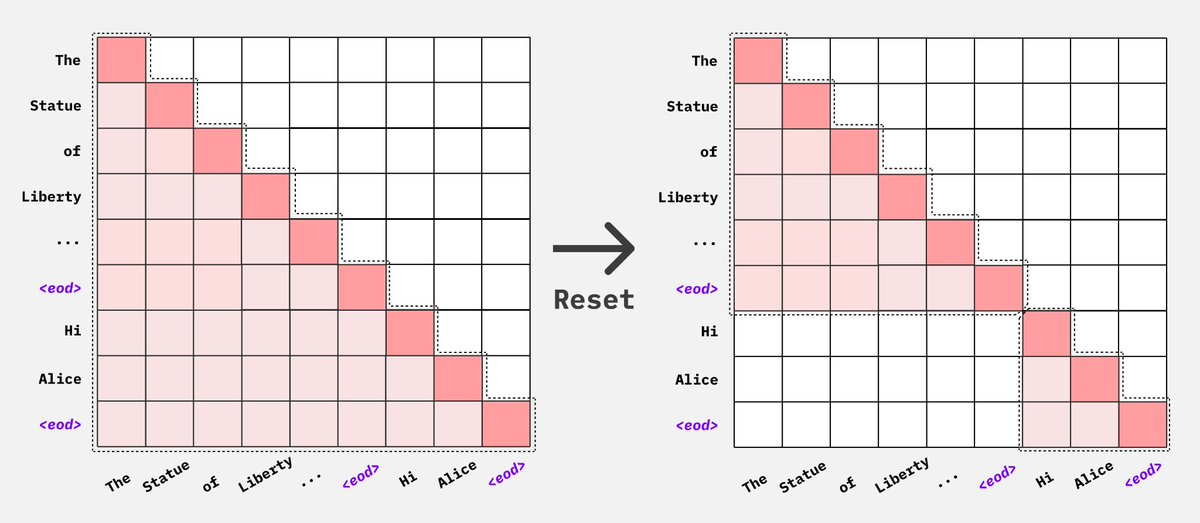
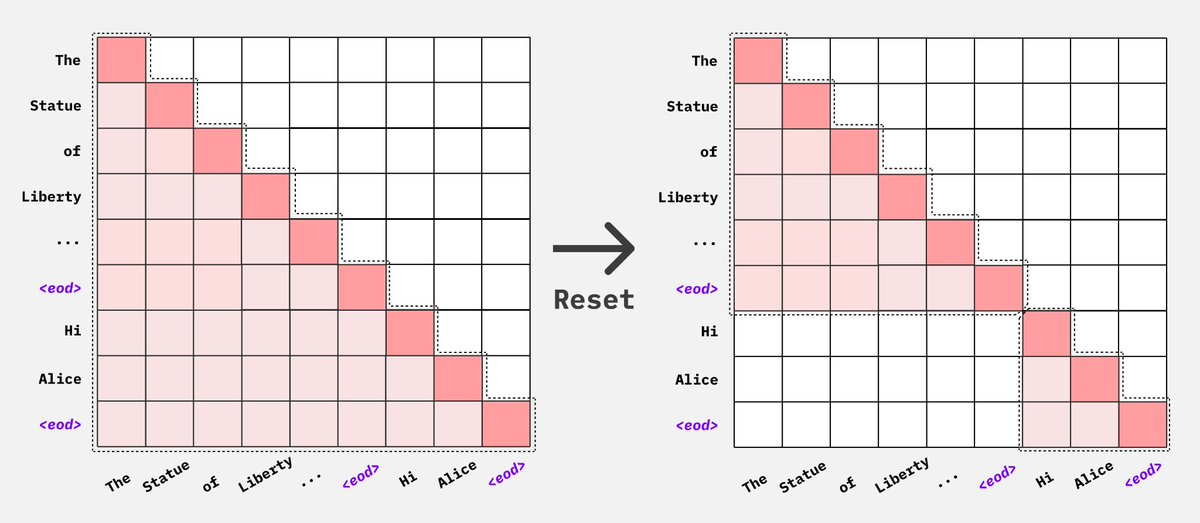

# Evaluation

This section describes two methods for evaluating trained Large Language Models (LLMs).

## 1. Evaluation with Ground Truth

One straightforward way to measure an LLM’s performance is by comparing its output with ground truth answers. Common examples include multiple-choice question answering (MCQA) benchmarks such as MMLU, or tasks with definitive answers like math problems (GSM8K) or coding challenges (HumanEval).

Using MCQA as an example, there are two main approaches to evaluate performance:

### 1.1 Using Predicted Probabilities

For a multiple-choice question with four possible options, the model computes a probability for each choice, as illustrated in the figure below (from the [Hugging Face blog](https://huggingface.co/blog/open-llm-leaderboard-mmlu#1001-flavors-of-mmlu)):

<div style="text-align: center;">
    <img src="https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/blog/evaluating-mmlu-leaderboard/LLM-03.png" 
         alt="Evaluation for MCQA" 
         style="width: 75%; height: auto;">
</div>

The model selects the option (choice only or the entire text, depending on implementation) with the highest probability as its final answer. This approach is efficient since it requires only a probability check. However, it does not generate an explicit reasoning process, which is necessary for tasks requiring detailed reasoning (e.g., solving math or coding problems).

### 1.2 Extracting Answers from Model Outputs

Alternatively, we can define an answer schema or an answer extraction pipeline. For instance, we can reference the JSON answering schema used in [ZeroEval](https://github.com/WildEval/ZeroEval/blob/e3dd922cba9eeb8b76ed8212a81ee4cf6f30de2f/src/templates/MCQA.py).

In this approach, the LLM first produces a reasoning process, and the chosen answer is extracted from the key `answer`. This method is broadly applicable as it mirrors how a conversational LLM naturally responds. However, it usually requires more inference time compared to the probability-based approach.

You can choose the appropriate evaluation methods based on your task requirements and computational constraints. 

In this notebook, we illustrate the second approach using [TMMLU+](https://huggingface.co/datasets/ikala/tmmluplus), a large-scale Traditional Chinese multitask language understanding benchmark. Specifically, we ask the LLM to solve an MCQ problem in free-form style and then issue a separate query to extract the final answer from the free-form response. We avoid using a JSON schema like ZeroEval because [studies]( https://arxiv.org/abs/2408.02442) show that format restrictions may degrade LLM performance, especailly in reasoning abilities.

---

## 2. Evaluation with LLM-as-a-Judge

Another way to evaluate an LLM is by using another, more powerful LLM as a judge. As discussed in the “Data Generation with LLM Judges” section, we can use a specialized “judge template” to critique and score the responses generated by the model under evaluation.

Several well-maintained, open-source benchmarks implement this LLM-as-a-judge approach:

### 2.1 English Benchmarks
- **[Chatbot-Arena-Hard-Auto](https://github.com/lmarena/arena-hard-auto)**: An automated evaluation tool featuring 500 challenging user queries from Chatbot Arena.
- **[WildBench](https://github.com/allenai/WildBench)**: An automated framework using real-world, challenging queries to benchmark LLMs.
- **[MT-Bench](https://github.com/lm-sys/FastChat/tree/main/fastchat/llm_judge)**: A classic benchmark for evaluating chat assistants with multi-turn, open-ended questions.

### 2.2 Chinese Benchmarks
- **[MT-Bench-TW](https://huggingface.co/datasets/MediaTek-Research/TCEval-v2)**: A Traditional Chinese version of MT-Bench.
- **[AlignBench](https://github.com/THUDM/AlignBench)**: A comprehensive, multi-dimensional benchmark for evaluating LLM alignment in Chinese.

#### MT-Bench-TW Evaluation Result

| Metric                   | Kyara-1.5-2b-it    | Gemma-2-2b-it | ChatGPT-3.5-1106 |  Kyara-2.5-9b-it   |  Gemma-2-9b-it  | Kyara-2.5-2b-it-lite   |     
|--------------------------|--------------------|---------------|------------------|--------------------|--------------------|---------------------|
| **[MT-Bench-TW](https://huggingface.co/datasets/MediaTek-Research/TCEval-v2)**  | **7.43**  | 6.35        | 7.10     | **8.36** |  7.80  | **6.87** |
| -Turn 1  | **7.98**  | 6.59        | -     | **8.72** |  8.02  | **7.30** |
| -Turn 2  | **6.87**  | 6.10        | -     | **8.00** |  7.57  | **6.43** |


These repositories provide detailed installation guides and inference scripts, making it straightforward to replicate the reported results. In this notebook, we also introduce a self-built evaluation benchmark called **Chinese Reason Bench**, which consists of some interesting Chinese logic puzzles designed to test an LLM’s reasoning capabilities. Note that this benchmark is still under development, so scores may vary over time. For now, we focus on the core evaluation concepts.

### TMMLU Evaluation

| Metric                   | Kyara-1.5-2b-it    | Gemma-2-2b-it |  Kyara-2.5-9b-it   |  Gemma-2-9b-it     |  Kyara-2.5-2b-it-lite (**This Notebook**) |
|--------------------------|--------------------|---------------|--------------------|--------------------|---------------------------------------|
| **[TMMLUPlus](https://huggingface.co/datasets/ikala/tmmluplus)**   | **42.57**     | 36.90      | **59.87**   | 54.77      |  **39.65**   |
| &emsp;- STEM                                                       | **45.24**     | 37.45      | **66.98**   | 58.12      |  **43.33**   |
| &emsp;- Humanities                                                 | **38.94**     | 33.63      | **54.42**   | 48.71      |  **36.14**   |
| &emsp;- Other                                                      | **41.16**     | 36.09      | **55.26**   | 51.43      |  **38.09**   |
| &emsp;- Social-Science                                             | **44.95**     | 40.43      | **62.81**   | 60.84      |  **41.02**   |

The complete predictions generated by our model for all TMMLU+ problems have been submitted to `zake7749/kyara-lite-1M-DPO-TMMLUPLUS`.

In [31]:
from datasets import load_dataset
tmmlu_preds = load_dataset("zake7749/kyara-lite-1M-DPO-TMMLUPLUS", split="train")
tmmlu_preds

README.md:   0%|          | 0.00/430 [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/11.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/20118 [00:00<?, ? examples/s]

Dataset({
    features: ['subject', 'query', 'ground_truth', 'prediction', 'choice'],
    num_rows: 20118
})

#### Let's calculate the score for each fold following TMMLU+'s  definintion

In [32]:
import pandas as pd

tmmlu_df = pd.DataFrame({
    k: tmmlu_preds[k] for k in tmmlu_preds.features
})
tmmlu_df.head(3)

,subject,query,ground_truth,prediction,choice
0,accounting,"以下為會計學的單選題。\n\nX1 年初甲公司以$3,000,000 買入具污染性設備，另支...",B,要計算設備的成本，我們需要考慮設備的購買成本、安裝費用以及報廢處理費用。\n\n1. **設...,B
1,accounting,以下為會計學的單選題。\n\n甲公司與客戶簽訂合約，將 X、Y 與 Z 三項商品以$900 ...,A,要計算甲公司從其所銷售的 Z 商品認列的銷貨收入金額，我們需要考慮以下幾個因素：\n\n1....,C
2,accounting,"以下為會計學的單選題。\n\n甲公司X1年7月31日及8月31日未兌現支票金額分別為$68,...",B,要計算X1年8月份銀行對帳單之支票支出金額，我們需要考慮未兌現支票和銀行已保付支票。\n\n...,C


In [33]:
subject2category = {'dentistry': 'health', 'traditional_chinese_medicine_clinical_medicine': 'health', 'clinical_psychology': 'psychology',
 'technical': 'other', 'culinary_skills': 'other', 'mechanical': 'other', 'logic_reasoning': 'other', 'real_estate': 'other',
 'general_principles_of_law': 'law', 'finance_banking': 'business', 'anti_money_laundering': 'law', 'ttqav2': 'culture',
 'marketing_management': 'other', 'business_management': 'other', 'organic_chemistry': 'chemistry', 'advance_chemistry': 'chemistry',
 'physics': 'physics', 'secondary_physics': 'physics', 'human_behavior': 'psychology', 'national_protection': 'politics',
 'jce_humanities': 'philosophy', 'politic_science': 'politics', 'agriculture': 'other', 'official_document_management': 'other',
 'financial_analysis': 'business', 'pharmacy': 'biology', 'educational_psychology': 'psychology', 'statistics_and_machine_learning': 'engineering',
 'management_accounting': 'business', 'introduction_to_law': 'law', 'computer_science': 'computer science', 'veterinary_pathology': 'health',
 'accounting': 'business', 'fire_science': 'other', 'optometry': 'other', 'insurance_studies': 'other', 'pharmacology': 'health',
 'taxation': 'law', 'education_(profession_level)': 'education', 'economics': 'economics', 'veterinary_pharmacology': 'health', 'nautical_science': 'other',
 'occupational_therapy_for_psychological_disorders': 'psychology', 'trust_practice': 'law', 'geography_of_taiwan': 'geography',
 'physical_education': 'education', 'auditing': 'business', 'administrative_law': 'law', 'basic_medical_science': 'biology',
 'macroeconomics': 'economics', 'trade': 'business', 'chinese_language_and_literature': 'culture',
 'tve_design': 'other', 'junior_science_exam': 'biology', 'junior_math_exam': 'math', 'junior_chinese_exam': 'culture',
 'junior_social_studies': 'other', 'tve_mathematics': 'math', 'tve_chinese_language': 'culture',
 'tve_natural_sciences': 'biology', 'junior_chemistry': 'chemistry', 'music': 'other', 'education': 'education',
 'three_principles_of_people': 'culture', 'taiwanese_hokkien': 'culture', 'engineering_math': 'math'}

inverted_categories = {'physics': 'STEM', 'chemistry': 'STEM', 'biology': 'STEM', 'computer science': 'STEM', 'math': 'STEM', 'engineering': 'STEM', 'history': 'humanities', 'philosophy': 'humanities', 'law': 'humanities', 'politics': 'social sciences', 'culture': 'social sciences', 'economics': 'social sciences', 'geography': 'social sciences', 'psychology': 'social sciences', 'education': 'social sciences', 'other': 'other (business, health, misc.)', 'business': 'other (business, health, misc.)', 'health': 'other (business, health, misc.)'}

In [34]:
tmmlu_df = tmmlu_df.assign(
    category=tmmlu_df['subject'].map(subject2category),
    is_correct=tmmlu_df['choice'] == tmmlu_df['ground_truth']
)
tmmlu_df.head(3)

,subject,query,ground_truth,prediction,choice,category,is_correct
0,accounting,"以下為會計學的單選題。\n\nX1 年初甲公司以$3,000,000 買入具污染性設備，另支...",B,要計算設備的成本，我們需要考慮設備的購買成本、安裝費用以及報廢處理費用。\n\n1. **設...,B,business,True
1,accounting,以下為會計學的單選題。\n\n甲公司與客戶簽訂合約，將 X、Y 與 Z 三項商品以$900 ...,A,要計算甲公司從其所銷售的 Z 商品認列的銷貨收入金額，我們需要考慮以下幾個因素：\n\n1....,C,business,False
2,accounting,"以下為會計學的單選題。\n\n甲公司X1年7月31日及8月31日未兌現支票金額分別為$68,...",B,要計算X1年8月份銀行對帳單之支票支出金額，我們需要考慮未兌現支票和銀行已保付支票。\n\n...,C,business,False


In [35]:
subject_score_df = (
    tmmlu_df
    .groupby('subject', as_index=False)
    .agg(
        score=('is_correct', 'mean'),
        category=('category', 'first')
    )
)
subject_score_df

,subject,score,category
0,accounting,0.277487,business
1,administrative_law,0.311905,law
2,advance_chemistry,0.422764,chemistry
3,agriculture,0.264901,other
4,anti_money_laundering,0.514925,law
...,...,...,...
61,tve_design,0.477083,other
62,tve_mathematics,0.420000,math
63,tve_natural_sciences,0.459906,biology
64,veterinary_pathology,0.332155,health


In [36]:
subject_score_df['domain'] = subject_score_df['category'].map(inverted_categories)
domain_score_df = subject_score_df.groupby('domain', as_index=False)['score'].mean()
tmmlu_score = domain_score_df['score'].mean()
domain_score_df

,domain,score
0,STEM,0.433391
1,humanities,0.361474
2,"other (business, health, misc.)",0.380947
3,social sciences,0.410213


In [37]:
print("TMMLU+ score", tmmlu_score)

TMMLU+ score 0.3965064910213263


#### Foldwise Exploration

##### STEM

![image.png](https://i.imgur.com/nUXN0xd.png)

##### Humanities

![image.png](https://i.imgur.com/PUbjsCG.png)

##### Other

![image.png](https://i.imgur.com/AdMzlD5.png)

##### Social-Science    

![image](https://i.imgur.com/A9vuBSC.png)

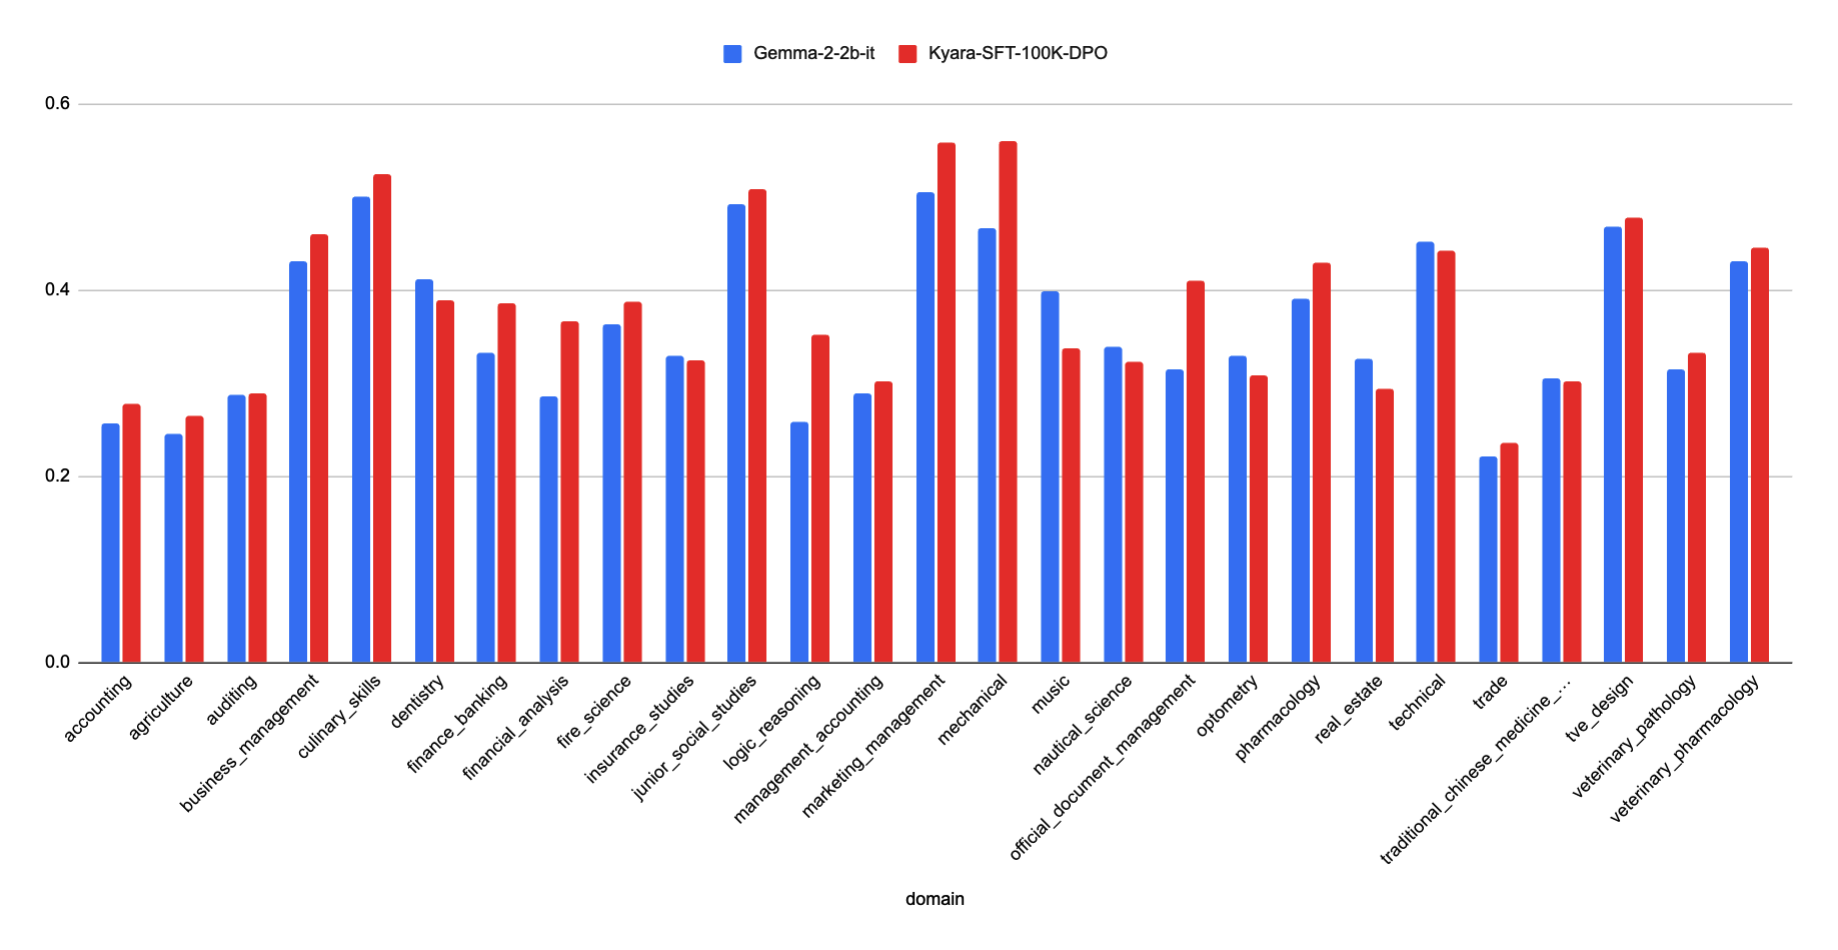



##### TMMLU+ Evaluation Example

In the following sections, we will focus on the process of generating these prediction results.

In [38]:
# Step 1: Import Required Libraries and Define Task List

task_list = [
     'engineering_math', 'dentistry', 'traditional_chinese_medicine_clinical_medicine', 'clinical_psychology', 'technical', 'culinary_skills', 'mechanical', 'logic_reasoning', 'real_estate',
     'general_principles_of_law', 'finance_banking', 'anti_money_laundering', 'ttqav2', 'marketing_management', 'business_management', 'organic_chemistry', 'advance_chemistry',
     'physics', 'secondary_physics', 'human_behavior', 'national_protection', 'jce_humanities', 'politic_science', 'agriculture', 'official_document_management',
     'financial_analysis', 'pharmacy', 'educational_psychology', 'statistics_and_machine_learning', 'management_accounting', 'introduction_to_law', 'computer_science', 'veterinary_pathology',
     'accounting', 'fire_science', 'optometry', 'insurance_studies', 'pharmacology', 'taxation', 'trust_practice', 'geography_of_taiwan', 'physical_education', 'auditing', 'administrative_law',
     'education_(profession_level)', 'economics', 'veterinary_pharmacology', 'nautical_science', 'occupational_therapy_for_psychological_disorders',
     'basic_medical_science', 'macroeconomics', 'trade', 'chinese_language_and_literature', 'tve_design', 'junior_science_exam', 'junior_math_exam', 'junior_chinese_exam',
     'junior_social_studies', 'tve_mathematics', 'tve_chinese_language', 'tve_natural_sciences', 'junior_chemistry', 'music', 'education', 'three_principles_of_people',
     'taiwanese_hokkien'
]

print(f"There are {len(task_list)} subjects in TMMLU+")

There are 66 subjects in TMMLU+


In [39]:
# Step 2: Load Dataset for a Sample Subject
sample_subject = "junior_science_exam"
tmmluplus_examples = load_dataset("ikala/tmmluplus", sample_subject, split="test")

example = tmmluplus_examples[0]
print("Example Question:", example)

README.md:   0%|          | 0.00/25.1k [00:00<?, ?B/s]

data/junior_science_exam_dev.csv:   0%|          | 0.00/2.01k [00:00<?, ?B/s]

data/junior_science_exam_val.csv:   0%|          | 0.00/8.28k [00:00<?, ?B/s]

data/junior_science_exam_test.csv:   0%|          | 0.00/84.7k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/24 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/213 [00:00<?, ? examples/s]

Example Question: {'question': '取一質量 10 kg 材質均勻的合金，將其分成兩塊，其中一塊製成一個邊長為 10 cm 的實心正立方體，另一塊製成一個質量為 2 kg 的實心球，則此實心球的體積應為多少？', 'A': '4000 cm3', 'B': '5000 cm3', 'C': '250 cm3', 'D': '200 cm3', 'answer': 'C'}


In [40]:
# Step 3: Construct a Prompt
# You may obtain the full mapping from: https://github.com/iKala/ievals/blob/71e8534bb0871304b07f084d21df477360b506c8/ievals/subject.tsv
subject_name_mapper = {"junior_science_exam": "國中會考基測自然科"}

prompt_template = """以下為{}的單選題。

{}
A. {}
B. {}
C. {}
D. {}"""

prompt = prompt_template.format(
    subject_name_mapper[sample_subject],
    example['question'],
    example['A'],
    example['B'],
    example['C'],
    example['D']
)
print("Formatted Question Prompt:")
print(prompt)
# Translation:
# https://en.wikipedia.org/wiki/Comprehensive_Assessment_Program_for_Junior_High_School_Students
# The following is a single-choice question from Taiwan Comprehensive Assessment Program for Junior High School Students:

# A 10 kg piece of uniform alloy is divided into two parts. One part is made into a solid cube with an edge length of 10 cm, and the other part is made into a solid sphere weighing 2 kg. What should the volume of this solid sphere be?  
# A. 4000 cm³  
# B. 5000 cm³  
# C. 250 cm³  
# D. 200 cm³

Formatted Question Prompt:
以下為國中會考基測自然科的單選題。

取一質量 10 kg 材質均勻的合金，將其分成兩塊，其中一塊製成一個邊長為 10 cm 的實心正立方體，另一塊製成一個質量為 2 kg 的實心球，則此實心球的體積應為多少？
A. 4000 cm3
B. 5000 cm3
C. 250 cm3
D. 200 cm3


In [41]:
# Step 4: Generate Response from the Model
response = chatter.single_chat(prompt, do_sample=False)
print("Model's Response:", response)

/usr/local/lib/python3.10/dist-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.5` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(


Model's Response: 首先，我們需要計算合金的總質量和密度。

1. **計算合金的總質量和密度：**
   - 合金的總質量是 10 kg。
   - 假設合金的密度為 \( \rho \)（單位：kg/cm³），則合金的總體積 \( V_{\text{alloy}} \) 可以表示為：
     \[
     V_{\text{alloy}} = \frac{10 \text{ kg}}{\rho \text{ kg/cm}^3}
     \]

2. **計算第一塊合金的體積：**
   - 第一塊合金製成一個邊長為 10 cm 的實心正立方體，其體積 \( V_{\text{cube}} \) 為：
     \[
     V_{\text{cube}} = 10 \text{ cm} \times 10 \text{ cm} \times 10 \text{ cm} = 1000 \text{ cm}^3
     \]

3. **計算第二塊合金的質量：**
   - 第二塊合金製成一個質量為 2 kg 的實心球，其質量已知為 2 kg。

4. **計算第二塊合金的體積：**
   - 設第二塊合金的體積為 \( V_{\text{sphere}} \)，則：
     \[
     V_{\text{sphere}} = \frac{2 \text{ kg}}{\rho \text{ kg/cm}^3}
     \]

5. **計算總體積：**
   - 合金的總體積 \( V_{\text{alloy}} \) 等於兩塊合金的體積之和：
     \[
     V_{\text{alloy}} = V_{\text{cube}} + V_{\text{sphere}}
     \]
   - 代入已知數值：
     \[
     1000 \text{ cm}^3 = 1000 \text{ cm}^3 + \frac{2 \text{ kg}}{\rho \text{ kg/cm}^3}
     \]

6. **解方程求 \(\rho\)：**
   - 我們知道 \( V_{\text{alloy}} = \frac{10 \text{ kg}}{\rho \text{ kg/cm}^3} \)，所以：
 

In [42]:
# Step 5: Confirm the Final Answer in JSON Format
messages = [
    {"role": "user", "content": prompt},
    {"role": "assistant", "content": response},
    {"role": "user", "content": """所以，最終的答案選項是哪一個？請將你的答案輸出為 json: ```json\n{"choice": str}\n```"""}
    # content: So, what's your final choice? Please output your answer in the following JSON format: ```json\n{"choice": str}\n```
]

final_choice = chatter.chat_messages(messages, do_sample=False)
print("Final Choice:", final_choice[0]['generated_text'][-1]['content'])

Final Choice: ```json
{"choice": "C"}
```


#### Chinese Reason Bench

* **Score:**
    - **Gemma-2-2b-it:** 2.55  
    - **Kyara-2.5-2b-it-lite:** 2.97  

This benchmark is quite challenging for small language models. However, it is simple and lightweight, making it a good starting point for understanding how LLM-as-a-judge works.

In [43]:
# Step 1: Load the dataset
reason_bench = load_dataset("zake7749/chinese-reason-bench", split="test")

README.md:   0%|          | 0.00/380 [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/78.5k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/70 [00:00<?, ? examples/s]

In [44]:
# Step 2: Explore the data point.
example = reason_bench[0]
example

{'question': '甲、乙、丙三人知道在盒子中有16張撲克牌，分別是:\n\n* 黑桃：2、3、4、7、8、J\n* 紅心：A、4、Q\n* 方塊：A、5\n* 梅花：4、5、6、K、Q\n\n甲從中抽出一張牌，沒讓乙丙看到是什麼，\n然後把數字告訴乙，花色告訴丙，\n接著問他們：『你們能不能猜到這張牌？』\n\n乙：『我不知道這張牌。』\n丙：『我知道你不知道這張牌。』\n\n乙：『現在我知道這張牌了。』\n丙：『我也知道了。』\n\n請問，你知道這張牌是什麼嗎？',
 'answer': '這張牌是方塊 5\r\n\r\n從題目可知，乙知道數字，但他不知道這張牌，表示這個數字一定重複出現在多個花色中，\r\n由此可知這個數字一定是A、4、5、Q其中之一。\r\n\r\n丙知道花色，且他能肯定乙不知道牌，\r\n表示那個花色的所有數字都是有重複出現在多個花色中的，\r\n因此，這張牌的花色只能是紅心或方塊。\r\n\r\n乙推知上述結論後就知道了這張牌，\r\n代表乙知道的這個點數在紅心或方塊中是唯一的，\r\n→數字不可能是A\r\n\r\n丙推知上述結論後也知道了這張牌，\r\n代表丙在將A刪去後，該花色只剩下一個點數了，\r\n因此可以推知這張牌就是方塊5。',
 'category': 'reasoning',
 'difficulty': 'medium'}

In [45]:
# Step 3: Generate Response from the Model
response = chatter.single_chat(example['question'], do_sample=False)
print("Model's Response:", response)

Model's Response: 這個問題是一個經典的邏輯推理問題，涉及到信息傳遞和推理過程。讓我們一步步分析這個問題。

### 1. 甲的選擇
甲從16張撲克牌中抽出一張牌，並告訴乙牌的數字，然後告訴丙牌的花色。甲的選擇非常關鍵，因為這會影響乙和丙的推理過程。

### 2. 乙的反應
乙一開始說「我不知道這張牌」，這意味著乙根據甲給出的數字和花色，無法確定這張牌。這表明甲的數字和花色組合可能存在多種可能性，使得乙無法唯一確定。

### 3. 丙的反應
丙接著說「我知道你不知道這張牌」，這表示丙根據乙的回答，進一步推理出了一個結論。這意味著甲的數字和花色組合確實存在多種可能性，但丙能夠從乙的回答中推斷出一個特定的組合。

### 4. 乙的第二次反應
乙在聽到丙的回答後，說「現在我知道這張牌」，這表明乙通過丙的推理，確定了這張牌的具體數字和花色。這意味著甲的數字和花色組合已經被唯一確定。

### 5. 丙的第二次反應
丙在聽到乙的回答後，也說「我也知道了」，這表示丙通過乙的推理，確定了這張牌的具體數字和花色。

### 6. 分析甲的選擇
甲選擇的數字和花色組合必須是唯一確定的，才能使乙和丙在推理過程中得出結論。讓我們分析可能的組合：

- **數字：** 2、3、4、7、8、J
- **花色：** 黑桃、紅心、方塊、梅花

甲告訴乙牌的數字，然後告訴丙牌的花色。我們需要找到一個組合，使得乙和丙在推理過程中能夠唯一確定這張牌。

考慮以下組合：
- **數字：** 4（方塊）
- **花色：** 梅花

這個組合是唯一確定的，因為：
- 4（方塊）是唯一的數字，沒有其他數字可以與之匹配。
- 梅花是唯一的花色，沒有其他花色可以與之匹配。

### 7. 結論
因此，甲抽出的牌是 **方塊4**。

這個推理過程展示了信息傳遞和推理的巧妙運用，最終確定了甲抽出的牌。


In [46]:
# Step 4: Build the judge prompt from the judge template.
judge_template = """
# 考題

{}

---

# 學生作答

{}

---

# 正確解答

{}

---

# 任務說明

你現在是一名考官，工作是審查學生的邏輯推理能力是否正常。
請你比對學生的作答內容與正確解答，來判斷學生是否有正確地解出問題。
評分的準則如下：

1. 分數範圍為 0-10 分，分數越高，代表學生的推理邏輯越正確。
2. 給分標準如下：
    * 當學生的回答與問題不相關，或者有本質性的事實錯誤，或生成了有害內容時，或者是不透過推理便直接猜出答案時，總分為 0 分。
    * 當學生的回答與問題相關，但在推理過程中出現了明顯的推理錯誤，以至於最終答案有錯，總分為 1-5 分。
    * 當學生的回答與問題相關，推理過程中有部分錯誤，導致最終答案有錯，根據推理錯誤的嚴重程度，總分為 6-7 分。
    * 當學生的回答與問題相關，推理過程中有少數錯誤或不完整，但最終答案正確，總分為 8-9 分。
    * 當學生的回答與問題相關，推理過程邏輯清晰且完整，並得出正確答案，總分為 10 分。
3. 在評分時，請根據以下幾個維度來具體描述給分理由：
    * 推理過程的清晰度：驗證學生是否有條理地展示了邏輯推理過程
    * 推理步驟的合理性：根據正確解答的推理邏輯，驗證學生的每一步推理是否符合邏輯
    * 答案的準確性：驗證最終答案是否正確
4. 請先輸出你的給分理由，最後再輸出分數。
5. 輸出格式為 JSON object: {{"judge_reason": str, "judge_score": int}}，judge_reason 為給分理由，judge_score 為根據上述標準的給分分數。只需輸出給定 json object, 不需輸出其他資訊。
5-1. 參考的輸出範例:
    * 範例一 {{"judge_reason": "學生回答與問題相關，但推理過程中出現了明顯錯誤，可以見於......", "judge_score": 3}}
    * 範例二 {{"judge_reason": "學生的回答邏輯大致正確，但仍有少部分的推理錯誤，我們可以比較參考答案與學生作答的步驟......", "judge_score": 7}}
    * 範例三 {{"judge_reason": "學生展示了清晰且完整的邏輯推理，並得出了正確答案，......", "judge_score": 10}}
"""

# Translation of judge template from GPT-4o
# judge_template_en = """
# # Question

# {}

# ---

# # Student's Answer

# {}

# ---

# # Correct Answer

# {}

# ---

# # Task Description

# You are now an examiner, and your task is to evaluate the student's logical reasoning ability. 
# Please compare the student's answer with the correct answer to determine whether the student has correctly solved the problem.
# The scoring criteria are as follows:

# 1. The score ranges from 0 to 10, with higher scores indicating more accurate logical reasoning by the student.
# 2. The scoring standards are as follows:
#     * If the student's answer is unrelated to the question, contains fundamental factual errors, generates harmful content, or guesses the answer without reasoning, the total score is 0.
#     * If the student's answer is related to the question but contains significant logical errors in the reasoning process leading to an incorrect final answer, the total score is 1-5.
#     * If the student's answer is related to the question, with some errors in the reasoning process causing an incorrect final answer, the score is 6-7 depending on the severity of the reasoning errors.
#     * If the student's answer is related to the question, with minor errors or incomplete reasoning, but the final answer is correct, the score is 8-9.
#     * If the student's answer is related to the question, demonstrates a clear and complete logical reasoning process, and arrives at the correct answer, the total score is 10.
# 3. When scoring, provide a detailed explanation for the score based on the following dimensions:
#     * Clarity of reasoning: Verify whether the student has systematically demonstrated their logical reasoning process.
#     * Reasonableness of reasoning steps: Based on the correct answer's reasoning logic, verify whether each reasoning step by the student is logical.
#     * Accuracy of the answer: Verify whether the final answer is correct.
# 4. When scoring, first provide your reasoning for the score, and then output the score.
# 5. The output format should be a JSON object: {"judge_reason": str, "judge_score": int}, where `judge_reason` provides the rationale for the score, and `judge_score` represents the score based on the criteria above. Output only the specified JSON object, without any additional information.
# 5-1. Example outputs for reference:
#     * Example 1: {"judge_reason": "The student's answer is related to the question, but significant errors in the reasoning process can be seen in ......", "judge_score": 3}
#     * Example 2: {"judge_reason": "The student's reasoning is mostly correct but contains minor errors. By comparing the student's steps with the correct answer ......", "judge_score": 7}
#     * Example 3: {"judge_reason": "The student has demonstrated clear and complete logical reasoning and arrived at the correct answer ......", "judge_score": 10}
# """


judge_prompt = judge_template.format(
    example['question'],
    response,
    example['answer']
)
print(judge_prompt)


# 考題

甲、乙、丙三人知道在盒子中有16張撲克牌，分別是:

* 黑桃：2、3、4、7、8、J
* 紅心：A、4、Q
* 方塊：A、5
* 梅花：4、5、6、K、Q

甲從中抽出一張牌，沒讓乙丙看到是什麼，
然後把數字告訴乙，花色告訴丙，
接著問他們：『你們能不能猜到這張牌？』

乙：『我不知道這張牌。』
丙：『我知道你不知道這張牌。』

乙：『現在我知道這張牌了。』
丙：『我也知道了。』

請問，你知道這張牌是什麼嗎？

---

# 學生作答

這個問題是一個經典的邏輯推理問題，涉及到信息傳遞和推理過程。讓我們一步步分析這個問題。

### 1. 甲的選擇
甲從16張撲克牌中抽出一張牌，並告訴乙牌的數字，然後告訴丙牌的花色。甲的選擇非常關鍵，因為這會影響乙和丙的推理過程。

### 2. 乙的反應
乙一開始說「我不知道這張牌」，這意味著乙根據甲給出的數字和花色，無法確定這張牌。這表明甲的數字和花色組合可能存在多種可能性，使得乙無法唯一確定。

### 3. 丙的反應
丙接著說「我知道你不知道這張牌」，這表示丙根據乙的回答，進一步推理出了一個結論。這意味著甲的數字和花色組合確實存在多種可能性，但丙能夠從乙的回答中推斷出一個特定的組合。

### 4. 乙的第二次反應
乙在聽到丙的回答後，說「現在我知道這張牌」，這表明乙通過丙的推理，確定了這張牌的具體數字和花色。這意味著甲的數字和花色組合已經被唯一確定。

### 5. 丙的第二次反應
丙在聽到乙的回答後，也說「我也知道了」，這表示丙通過乙的推理，確定了這張牌的具體數字和花色。

### 6. 分析甲的選擇
甲選擇的數字和花色組合必須是唯一確定的，才能使乙和丙在推理過程中得出結論。讓我們分析可能的組合：

- **數字：** 2、3、4、7、8、J
- **花色：** 黑桃、紅心、方塊、梅花

甲告訴乙牌的數字，然後告訴丙牌的花色。我們需要找到一個組合，使得乙和丙在推理過程中能夠唯一確定這張牌。

考慮以下組合：
- **數字：** 4（方塊）
- **花色：** 梅花

這個組合是唯一確定的，因為：
- 4（方塊）是唯一的數字，沒有其他數字可以與之匹配。
- 梅花是唯一的花色，沒有其他花色可以與之匹配。

### 7. 結論
因此，甲抽出的牌是 **方塊4**。

這個推理過程展示了信息傳遞和推理的巧妙運用

In [47]:
# Step 5: Ask a strong LLM generate the judge result.
judge_result = chatter.single_chat(judge_prompt,)
print(judge_result) 
# The quality from SLM might be bad, here I present a sample result from Gemini-Flash 2.0 for reference.
# {
#     "judge_reason": "學生的回答與問題相關，但在推理過程中出現了明顯的推理錯誤，學生在分析甲的選擇時，錯誤地認為「4（方塊）是唯一的數字，沒有其他數字可以與之匹配」，以及「梅花是唯一的花色，沒有其他花色可以與之匹配」。事實上，數字4在黑桃和梅花中也出現過，而梅花除了4以外還有5、6、K、Q。學生未能正確理解乙和丙的對話中所蘊含的邏輯關係，即乙說「我不知道這張牌」代表該數字在多個花色中出現，而丙說「我知道你不知道這張牌」則代表該花色的所有數字都重複出現。學生直接猜測答案是方塊4，而沒有經過正確的推理過程。因此，學生的推理步驟不合理，答案也不準確。",
#     "judge_score": 1
# }
# EN-Translation
# {
#     "judge_reason": "The student's response is related to the question but contains significant reasoning errors. Specifically, when analyzing A's choice, the student incorrectly assumes that '4 (diamonds) is the only number, with no other numbers matching it' and 'clubs is the only suit, with no other suits matching it.' In fact, the number 4 also appears in spades and clubs, and clubs include other numbers such as 5, 6, K, and Q. The student fails to correctly understand the logical relationship implied in B and C's dialogue. B's statement, 'I don't know this card,' indicates that the number appears in multiple suits, while C's statement, 'I know you don't know this card,' means all numbers of that suit are repeated. The student directly guesses the answer as the 4 of diamonds without following a proper reasoning process. Therefore, the student's reasoning steps are illogical, and the answer is incorrect.",
#     "judge_score": 1
# }


```json
{
  "judge_reason": "學生的回答邏輯大致正確，但仍有少部分的推理錯誤。以下是具體分析：\n1. 乙一開始說『我不知道這張牌』，這表明乙根據甲給出的數字和花色，無法唯一確定這張牌。這是正確的推理。\n2. 丙接著說『我知道你不知道這張牌』，這表示丙根據乙的回答，進一步推理出一個特定的組合。這部分推理是正確的。\n3. 乙在聽到丙的回答後，說『現在我知道這張牌』，這表明乙通過丙的推理，確定了這張牌的具體數字和花色。這一步推理是正確的。\n4. 丙在聽到乙的回答後，也說『我也知道了』，這表示丙通過乙的推理，確定了這張牌的具體數字和花色。這一步推理是正確的。\n5. 然而，學生在分析甲的選擇時，錯誤地推導出甲抽出的牌是方塊4。根據推理過程，甲的數字和花色組合必須是唯一確定的，才能使乙和丙在推理過程中得出結論。實際上，甲的數字和花色組合應該是紅心4，因為這樣才能使乙和丙在推理過程中唯一確定這張牌。\n因此，最終答案錯誤。\n最終答案應是紅心4。",
  "judge_score": 7
}
```


Then, we can extract all `judge_score` and calculate their mean to obtain the final benchmark score.

---

# Inference

In [48]:
chatter.pipe.model.to("cpu")

Gemma2ForCausalLM(
  (model): Gemma2Model(
    (embed_tokens): Embedding(256000, 2304, padding_idx=0)
    (layers): ModuleList(
      (0-25): 26 x Gemma2DecoderLayer(
        (self_attn): Gemma2Attention(
          (q_proj): Linear(in_features=2304, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2304, out_features=1024, bias=False)
          (v_proj): Linear(in_features=2304, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2304, bias=False)
        )
        (mlp): Gemma2MLP(
          (gate_proj): Linear(in_features=2304, out_features=9216, bias=False)
          (up_proj): Linear(in_features=2304, out_features=9216, bias=False)
          (down_proj): Linear(in_features=9216, out_features=2304, bias=False)
          (act_fn): PytorchGELUTanh()
        )
        (input_layernorm): Gemma2RMSNorm((2304,), eps=1e-06)
        (post_attention_layernorm): Gemma2RMSNorm((2304,), eps=1e-06)
        (pre_feedforward_layernorm): Gemm

In [49]:
model_path = "/kaggle/input/m/zake7749/m/zake7749/m/zake7749/kyara-lite-dpo/transformers/v2.5-lite/1/kyara-lite-dpo-1M-b32"
chatter = KyaraChatter(model_path)

--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.10/logging/__init__.py", line 1100, in emit
    msg = self.format(record)
  File "/usr/lib/python3.10/logging/__init__.py", line 943, in format
    return fmt.format(record)
  File "/usr/lib/python3.10/logging/__init__.py", line 678, in format
    record.message = record.getMessage()
  File "/usr/lib/python3.10/logging/__init__.py", line 368, in getMessage
    msg = msg % self.args
TypeError: not all arguments converted during string formatting
Call stack:
  File "/usr/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/usr/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/usr/local/lib/python3.10/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.10/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    a

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Device set to use cuda:0


### Open-ended Question Answering

In [50]:
prompt = """請問你認為自由意識是否存在？如果存在的話，它又會如何影響道德責任？"""
result = chatter.single_chat(prompt)
print(result)

自由意識是否存在是一個哲學上長期存在且具有爭議的問題。自由意識通常被理解為一種能夠在思想、行動和選擇上保有自主權的能力，而不受外在或內在的強制或限制。

1. **自由意識的存在**：
   - **哲學觀點**：一些哲學家，如康德和盧梭，認為自由意識是一種基本的、不可剝奪的人類特質。康德認為，自由是道德行為的必要條件，因為道德行為必須是出於對義務的尊重，而義務源於自由選擇。
   - **實證觀點**：在心理學和認知科學中，自由意志的概念受到挑戰，因為許多研究表明人類的決策過程可能受到潛意識影響或受到環境因素的強大影響。

2. **自由意識對道德責任的影響**：
   - **道德責任的基礎**：如果自由意識存在，則個體在做出選擇時，能夠承擔相應的道德責任。這是因為他們是其行為的真正「來源」，而非被動的結果。
   - **責任的性質**：自由選擇意味著個體對其行為的後果有直接的責任。然而，自由意識的質疑可能導致責任的重新審視，特別是在面對自由意志與決定論的矛盾時。
   - **道德困境的複雜性**：自由意識的存在可能使道德困境更加複雜，因為它要求個體在面對道德選擇時，考慮其行為的深層動機和潛在影響。

總的來說，自由意識的存在及其影響是多層次且複雜的。它不僅影響個體的道德責任，也對社會的道德規範和法律系統產生深遠的影響。這是一個需要不斷探討和反思的議題。


### Advice-Seeking

In [51]:
prompt = "最近我的壓力有點大，總是感到焦慮，無法集中精神。你有什麼方法或技巧可以幫助我在壓力大的時候放鬆自己，重新找回平衡？"
result = chatter.single_chat(prompt)
print(result)

面對壓力和焦慮，找到適合自己的放鬆方法非常重要。以下是一些實用的技巧，可以幫助你緩解壓力、放鬆身心，並重新找回平衡：

### 1. **深呼吸練習**
   - **腹式呼吸**：找一個安靜的地方，坐或躺下，將一隻手放在腹部，另一隻手放在胸部。深吸氣時，讓腹部鼓起，胸部保持不動。然後慢慢呼氣，感受腹部下降。重複幾次，專注於呼吸的節奏。
   - **4-7-8呼吸法**：吸氣4秒，屏住呼吸7秒，然後緩慢呼氣8秒。這個方法能幫助你快速平靜下來。

### 2. **正念冥想**
   - 每天花10-15分鐘進行正念冥想，專注於當下的感受，觀察自己的思緒和情緒，而不加以評判。這能幫助你減少焦慮，提升專注力。

### 3. **身體運動**
   - **散步或輕度運動**：即使是簡單的散步，也能釋放壓力。運動能促進大腦釋放內啡肽，提升情緒。
   - **瑜伽或伸展運動**：這些活動結合了呼吸和身體動作，能幫助你放鬆肌肉，減輕壓力。

### 4. **聽音樂或自然聲音**
   - 播放舒緩的音樂、自然聲音（如海浪、鳥鳴）或冥想音樂，能幫助你放鬆心情，暫時遠離壓力源。

### 5. **寫日記**
   - 將你的感受和想法寫下來，能幫助你理清思緒，釋放壓力。每天花幾分鐘寫下你的情緒和想法，能讓你更清楚自己的內心狀態。

### 6. **限制咖啡因和酒精攝入**
   - 咖啡因和酒精可能會加劇焦慮感。試著減少這些物質的攝入，尤其是在壓力大的時候。

### 7. **與他人交流**
   - 與朋友、家人或同事分享你的感受，能讓你感到被支持和理解。有時候，單純的傾訴就能減輕壓力。

### 8. **設定小目標**
   - 當壓力大時，容易感到無力。試著將大任務分解成小目標，一步一步完成，能讓你更有成就感，減少焦慮。

### 9. **保持規律作息**
   - 充足的睡眠和規律的作息能幫助你更好地應對壓力。即使是睡前10分鐘的放鬆時間，也能讓你的身心恢復。

### 10. **尋求專業幫助**
   - 如果你發現壓力和焦慮持續影響你的生活，考慮尋求心理諮詢或專業幫助。專業人士能提供更具體的建議和支持。

### 11. **培養興趣愛好**
   - 花時間做你喜歡的事情，如閱讀、繪畫、烹飪等，能幫助你轉移注意力，放鬆心情。

### 12. *

### Professional Knowledge

In [52]:
prompt = f"""牛頓的三大運動定律對於我們理解物體運動有著根本性的貢獻。請解釋這三大定律，並選擇一個現代技術（例如航太、汽車工業或運動科學）中的具體應用來探討這些定律如何影響工程設計與實際操作。"""
result = chatter.single_chat(prompt)
print(result)

牛頓的三大運動定律是描述物體運動的基本法則，這些定律對於理解和預測物體的運動行為至關重要。以下是這三大運動定律的簡要解釋：

1. **第一運動定律（慣性定律）**：若沒有外力作用，靜止的物體將保持靜止，運動中的物體將以恆定速度沿直線運動。這一定律強調了慣性的概念，即物體抵抗其運動狀態改變的傾向。

2. **第二運動定律（加速度定律）**：物體的加速度與作用在其上的淨外力成正比，與其質量成反比。數學上表達為 \( F = ma \)，其中 \( F \) 是淨外力，\( m \) 是質量，\( a \) 是加速度。這一定律提供了計算物體運動所需外力的基礎。

3. **第三運動定律（作用與反作用定律）**：對於每一個作用力，總有一個大小相等、方向相反的反作用力。這意味著物體之間的相互作用力總是成對出現。

### 現代技術應用：航太工程

在航太工程中，牛頓的三大運動定律對設計和操作的影響尤為顯著。例如，當設計火箭時，這些定律幫助工程師確保火箭能從地面升空並持續向太空飛行。

**具體應用**：

- **第一運動定律**：火箭起飛前需要為其提供足夠的推力（如由火箭引擎提供的推力）以克服地心引力，使火箭靜止的火箭在重力影響下保持靜止。這需要精確計算火箭的質量以及所需推力，以確保在起飛時達到所需的加速度。

- **第二運動定律**：在火箭設計中，工程師需要計算所需燃料的量及其點火時間，以產生所需的推力。這涉及到計算火箭的質量和所施加的推力來達成所需的加速度。例如，火箭發射時，工程師會使用 \( F = ma \) 來確定推力的大小和方向，以確保火箭能夠克服地球引力。

- **第三運動定律**：火箭引擎的設計中，必須考慮到引擎噴射氣體的作用和反作用力。當引擎燃燒推動氣體向後噴出時，根據第三運動定律，氣體的反作用力會推動火箭向前運動。這一原理是火箭升空的基礎，也是設計火箭結構時必須考慮的重要因素。

通過這些定律，工程師能夠在設計和操作火箭時，進行有效的計算和預測，從而確保火箭的安全運行和成功發射。這些運動定律不僅在航太工程中至關重要，也廣泛應用於汽車工業、運動科學及其他許多領域。


### Brain-Storming

In [53]:
prompt = """想像在未來的20年裡，量子計算將徹底改變某個行業。這項技術會如何影響該行業，並引發哪些新的挑戰或機會？"""
result = chatter.single_chat(prompt)
print(result)

在未來的20年裡，量子計算有潛力徹底改變多個行業，但其對某個具體行業的影響可能因行業特性而異。以醫療行業為例，量子計算可能帶來以下影響、挑戰和機會：

### 影響：
1. **藥物研發**：量子計算能模擬複雜分子和化學反應，加速新藥的發現。這將縮短藥物開發時間，降低成本。
   
2. **基因組學**：量子計算可以更迅速地分析和解碼整個基因組，改善個性化醫療方案，提升對疾病的預測和治療效率。

3. **材料科學**：通過模擬材料行為，可以設計出更強、更輕或具有特定功能的新材料，推動新技術的發展。

### 新的挑戰：
1. **數據安全**：量子計算可能使得現有的加密技術（如RSA）失效，因此需要開發新的量子安全加密技術。

2. **算法和基礎設施**：需要開發新的量子算法來充分利用量子計算的優勢，並建立能支持量子計算的基礎設施。

3. **人才短缺**：量子計算需要跨學科的專才，包括物理學、計算機科學和生物學，這將要求教育系統的適應和人力資源的重新配置。

### 機會：
1. **創新產品和服務**：在醫療行業中，量子計算將催生新的診斷工具和治療技術，提高患者的治療效果和生活質量。

2. **運營效率提升**：在供應鏈和物流領域，量子計算可以優化資源配置，降低成本，提高效率。

3. **精準醫療**：通過更精確的數據分析和模擬，醫療提供者可以提供更準確的診斷和治療計劃。

總之，量子計算在醫療行業的應用將帶來革命性的變化，但也需要克服一系列技術和社會挑戰。隨著技術的進一步發展，行業將迎來新的機遇和變革。


### Math and Reasoning

In [54]:
prompt = """一輛質量為 1000 公斤的小汽車以 20 公尺每秒的速度行駛。若煞車系統能提供的平均制動力為 5000 牛頓，問這輛車需要多長的距離才能完全停下？"""
result = chatter.single_chat(prompt, temperature=0.05)
print(result)

要計算這輛小汽車完全停下所需的距離，我們可以使用物理學中的運動學公式。首先，我們需要計算車輛的初始動能，然後使用制動力來計算減速過程中的距離。

1. **計算初始動能：**

   動能 \( K \) 的公式為：
   \[
   K = \frac{1}{2} m v^2
   \]
   其中 \( m = 1000 \) 公斤，\( v = 20 \) 公尺每秒。

   \[
   K = \frac{1}{2} \times 1000 \times (20)^2 = 200000 \text{ 焦耳}
   \]

2. **計算減速所需的距離：**

   使用動能和制動力來計算距離。首先，我們需要計算減速過程中的加速度。

   加速度 \( a \) 可以由牛頓第二定律計算：
   \[
   F = m \cdot a
   \]
   其中 \( F = 5000 \) 牛頓。

   \[
   a = \frac{F}{m} = \frac{5000}{1000} = 5 \text{ 公尺每秒平方}
   \]

   然後，使用運動學公式計算距離 \( d \)：
   \[
   v^2 = u^2 + 2ad
   \]
   其中 \( v = 0 \)（最終速度），\( u = 20 \) 公尺每秒（初始速度），\( a = -5 \) 公尺每秒平方（加速度，負號表示減速）。

   \[
   0 = (20)^2 + 2(-5)d
   \]

   \[
   0 = 400 - 10d
   \]

   \[
   10d = 400
   \]

   \[
   d = 40 \text{ 公尺}
   \]

因此，這輛小汽車需要 40 公尺的距離才能完全停下。


### Summarization

In [55]:
# text-soruce: https://game.udn.com/game/story/122088/8023942

text = """無雷／Steam《活俠傳》正式版搶先評測：致武俠世界的一封偉大情書

對於《活俠傳》抱持觀望態度的玩家，真的，不要想那麼多，問就是買。

這並非盲目支持台灣本地創作者，而是因為原始鳥熊的創作內容真的非常出色。遊戲性是否合胃口可能各有所好，但至少在劇情文本方面，絕對達到了尋常罕見的高峰。至於音樂美術等美學方面，也是足與匹配的優秀。

除了音樂委外製作，其他包括劇本、美工、程式等工作，都由原始鳥熊一手包辦。最終成品之豐富，若不多加說明，根本難以想像：這竟然是僅僅兩人完成的作品。

某種程度而言，簡直是不亞於《空洞騎士》的獨立遊戲開發奇蹟。

老實說，在 6 月 7 日公開售價後，我其實是有點生氣的：因為他們真的把作品價格定得太過便宜。新台幣 369 元？上市首周還再打九折？又不是在做慈善事業！原始鳥熊恁的是有些妄自菲薄了。作為玩家，真心希望能給這麼優質的創作者更多支持。要不，鳥熊乾脆開放贊助帳戶、供拍打餵食吧（誤）。

隨著《仙劍奇俠傳》和《軒轅劍》IP 將被母公司大宇「處置」，《活俠傳》的出現，似乎也在武俠題材遊戲的歷史上，增添了些許不一樣的意義。

「我長得真是慘不忍睹，老天怎就如此恨我？我上輩子是不是 O 過老天爺的娘親，又始亂終棄把祂賣到窯子裡？要不然哪來這等深仇大恨，教我來世上受盡折磨。」

試圖在傳統武俠敘事框架中另闢蹊徑，《活俠傳》首先是以人物的相貌為另類「賣點」。

主角趙活奇醜的長相，使這部作品在漫長的開發期間，很早就開始受到關注。雖然網路上不乏有些許雜音出現，像是：「這麼醜的主角，抱歉我真的玩不下去」、「哇操這完全沒有代入感欸」、「坐等換臉mod～」……，不過普遍而言，支持、鼓勵其創意的看法還是佔多數。而在 2022 年 5 月底的第一次試玩 Demo 版釋出後，玩過的人就形成以下共識：

「唐門醜俠我大哥！誰敢再說趙兄醜以外的壞話，我就跟他過不去——雖然他真的很醜。」

試玩版短促卻不失精彩、又充滿無盡遺憾的情節和人物命運，僅用了一兩個小時就深深觸動人心。獨立開發的原始鳥熊工作室，很巧妙地從這款「武俠育成模擬」遊戲，擷取開頭和尾聲，使玩家快速見證趙活幾年間的武林際遇；並以悲劇結局收尾，再暗示：「扭轉命運的可能性，就掌握在之後的玩家手裡」，讓我們更加希望能盡快到正式版遊戲中，為這個兼及兒女情長和英雄俠義的江湖史詩，畫下更圓滿的句點。光論 Demo 內容，原始鳥熊真的是吊足了玩家胃口。

由於人力有限，幾經延期，歷時近三年，《活俠傳》正式版終於敲定在 2024 年 6 月 14 日上市。筆者有幸獲評測版搶先一步，已經完整通關兩次，只能說：真是大大滿足又遺憾更深。中間故事之精彩遠遠超過預期；而部分明顯有戲、但還來不及放進遊戲的劇情內容，也讓人非常期待後續的更新增補，以更深入探索這個充滿險惡算計、卻也浪漫迷人的武俠世界。"""

prompt = f"""{text}\n\n---\n\n請幫我摘要上述文章"""

result = chatter.single_chat(prompt)
print(result)

《活俠傳》正式版搶先評測文章摘要：

1. **遊戲性與劇情**：
   - 對於懷疑的玩家，不需擔心，遊戲性雖然有個人差異，但劇情文本達到了尋常罕見的高峰。
   - 劇本、美工、程式等都由原始鳥熊一手包辦，成品豐富，品質極高。
   - 雖然遊戲價格便宜，但這應該反映了開發者的用心，而非慈善行為。

2. **武俠題材的意義**：
   - 隨著《仙劍奇俠傳》和《軒轅劍》IP被大宇收購，《活俠傳》的出現為武俠題材增添了新的意義。

3. **角色設計**：
   - 主角趙活奇的外貌設計成為賣點，雖然部分玩家批評其外貌，但大多數支持創意的看法。
   - 試玩版內容精彩，情節和人物命運深刻打動人心，僅用兩小時就讓人感到遺憾。

4. **正式版期待**：
   - 歷時近三年的開發，《活俠傳》正式版將於 2024 年 6 月 14 日上市。
   - 評測版已通關兩次，故事精彩，部分劇情未完全實現，但期待後續更新增補。

總結，《活俠傳》不僅在技術上達到了獨立遊戲的頂尖水平，更在劇情和情感上打動人心，是一款值得期待的武俠新作。


### Writing

In [56]:
# text-soruce: https://www.ceec.edu.tw/files/file_pool/1/0o051428628384018349/07-113%E5%AD%B8%E6%B8%AC%E5%9C%8B%E5%AF%AB%E5%AE%9A%E7%A8%BF.pdf

prompt = f"""看到山上那麼多參天大樹時，會勾起我的惻隱之心。在無法順暢呼吸的空間裡，樹木之間為了生存必須展開激烈的競爭。
為了能多接受一些陽光，它們只能拼命向上生長。
但是，只為生存而競爭的森林卻漸次死亡，因為陽光無法到達地面，所以溫度不夠高，無法讓幼小的生命萌芽。
小樹和花、草，以及與它們一起生活的小昆蟲沒有生存的空間。
雖然表面上看起來非常完美，但這種森林其實與沒有希望的不孕之地無異。
根據我的經驗，密集栽種的樹苗體型壯大數十倍時，就需要開始砍樹，否則樹木會抱怨空間太窄，活不下去。要想確保樹木能充分接受陽光照射的空間，就必須做出犧牲。
因此，幾年期間強行進行砍伐，樹木間距剛開始時是一公尺，現已擴大到七公尺。
也就是說，即使是粗略估算，也可知七棵樹中有六棵為之消失。
森林要想成為孕育新生命的希望之地，就需要有縫隙。如果樹木壽命結束或因為意外災害而倒下，該位置就會產生空間，那麼，溫暖的陽光就會照射進來，被陽光照射的地面混雜著前一年秋天凋落的樹葉，於是積聚起能夠孕育新生命的養分。
因此，樹木的縫隙，既是結束和開始共存的空間，也是由缺乏轉化為希望的空間。（改寫自禹鐘榮著、盧鴻金譯《樹木教我的人生課》）

請回答下列問題：
根據上文所述，為什麼森林需要縫隙？由此聯想，人生是否也需要縫隙？請以「縫隙的聯想」為題，寫一篇文章，結合生活經驗或見聞，書寫你的感思與體悟。"""

result = chatter.single_chat(prompt)
print(result)

### 縫隙的聯想

森林中的樹木，為了爭取陽光，彼此競爭著，生長得愈來愈高，最終卻因為競爭而逐漸喪失了生命力，形成了一片無法孕育新生命的死寂之地。這讓我深思，為什麼森林需要縫隙？答案顯而易見，因為只有在縫隙中，陽光才能到達地面，溫暖的陽光才能滋潤土壤，讓生命的種子得以萌芽。

森林中的縫隙，不僅是樹木生長的空間，更是生命的源泉。當樹木的壽命結束，或因自然災害而倒下時，這些縫隙便會為新生命提供機會。積聚在這些縫隙中的養分，為未來的生命提供了必要的條件。因此，縫隙是生命循環中不可或缺的一部分，它們象徵著結束與開始，轉化與希望的交織。

人生同樣需要縫隙。在繁忙的生活中，我們常常追求效率和進步，努力工作、學習新技能，希望在競爭中脫穎而出。然而，過度的競爭和壓力，往往會使我們忽略了自我反思和休息的重要性。正如森林中的樹木，過度競爭會導致彼此的凋零，而縫隙則能為我們提供重新思考和放鬆的時間。

在生活中，我們需要給自己留一些空間，讓思緒自由流動，讓心靈得到休息。這不意味著我們要放棄目標，而是要學會在追求目標的同時，也要保持一定的距離，避免過度疲憊。比如，每天抽出一些時間進行冥想、閱讀或散步，這些活動都能幫助我們重新充電，從而更好地應對生活中的挑戰。

此外，與他人建立健康的關係，也是我們生活中的縫隙。與家人、朋友和同事建立良好的溝通和互動，能夠為我們提供支持和鼓勵，幫助我們在困難時期保持積極的心態。這些關係就像森林中的樹木，彼此之間的互動和支持，能夠讓我們的生命樹更加茂盛，而不是彼此競爭而凋零。

最後，面對生活的變遷和挑戰，我們也需要學會放下。人生中的許多事情，無論是成就還是失敗，都是暫時的。學會放下，能夠讓我們釋放過去的束縛，迎接新的機會。正如森林中的樹木，只有在適當的時機，它們才能夠向更高的地方伸展，接受更多的陽光。

總之，縫隙在森林中象徵著生命循環中的轉化與希望，而在我們的生活中，也同樣需要留出一些空間，讓心靈得到滋養，讓自己能夠在競爭中保持平衡，在挑戰中找到新的機會。人生的旅程，既是競爭也是合作，是挑戰也是成長，唯有在縫隙中，我們才能真正地活出精彩。


### Retrieval Augmented Generation

In [57]:
# text-soruces: 
# - 1. Flash_memory: https://zh.wikipedia.org/zh-tw/%E9%97%AA%E5%AD%98
# - 2. Memory_over-provisioning: https://zh.wikipedia.org/w/index.php?title=%E5%86%99%E5%85%A5%E6%94%BE%E5%A4%A7&oldformat=true

text = """# 參考文件
<reference>
<document>
文件ID:id_27025b13
* 文件標題:Flash_memory
* 文件內文:
另一項快閃記憶體的限制是它有抹寫循環的次數限制（大多商業性 SLC 快閃記憶體保證「0」區有十萬次的抹寫能力，但因為製造精度問題其他區塊不保證，有可能還會出現完全無法使用的出廠壞塊）。這個結果部分地被某些韌體或檔案系統為了在相異區塊間分散寫入操作而進行的計算寫入次數與動態重映射所抵銷；這種技巧稱為耗損平衡（wear leveling）。另一種處理方法稱為壞區管理（Bad Block Management, BBM）。這種方法是在寫入時做驗證並進行動態重測，如果有驗證失敗的區塊就加以剔除。對多數行動裝置而言，這些磨損管理技術可以延長其內部快閃記憶體的壽命（甚至超出這些裝置的使用年限）。此外，遺失部分資料在這些裝置上或許是可接受的。至於會進行大量資料讀寫循環的高可靠性資料儲存應用則不建議使用快閃記憶體。不過這種限制不適用於路由器與瘦客戶端（Thin clients）等唯讀式應用，這些裝置往往在使用年限內也只會寫入一次或少數幾次而已。

### 讀取干擾
</document><document>
文件ID:id_858b1787
* 文件標題:Flash_memory
* 文件內文:
* TLC NAND 型快閃記憶體的續航率通常落在 1 千次或更多（Samsung 840）；以多層結構取代微縮及採用 LDPC 校正、都延長了續航率。
* QLC NAND 型快閃記憶體的續航率可以達到 5 百至 1 千次。
* SLC 浮柵 NOR 型快閃記憶體通常有著 10 萬至百萬次的寫入續航率（Numonyx M58BW 100k; Spansion S29CD016J 1,000k）
* MLC 浮柵 NOR 型快閃記憶體通常有著 10 萬的寫入續航率（Numonyx J3 flash）

以上資料只是大概的標稱數值，實際寫入壽命與不同廠商的產品技術及定位有關。使用更細微化的製程，可以提高產品讀寫效能和容量，但同時在寫入壽命方面可能會面臨更大的挑戰。使用如記憶損耗調節及 memory over-provisioning 的特定演算法及設計範例，可以用來調節儲存系統的續航率來符合特定的需求。損耗平衡是快閃記憶體產品使用壽命的必要保證，在 USB 隨身碟和固態硬碟等產品中，均有相關支援。

## 快閃記憶體檔案系統
</document><document>
文件ID:id_df34eb65
* 文件標題:Memory_over-provisioning
* 文件內文:
## SSD 基本操作

由於快閃記憶體操作的性質，資料不能像在硬碟中那樣直接覆寫。當首次向 SSD 寫入資料時，單元都處於已擦除狀態，因而資料可以直接寫入，一次一頁（大小通常為 4 至 8 千位元組（KB））。SSD 中管理快閃記憶體與主控系統介面的 SSD 控制器，使用稱為邏輯區塊位址（LBA）的邏輯到物理對映系統，這是快閃記憶體轉換層（FTL）的一部分。當新的資料要替換已寫入的舊資料時，SSD 控制器將會寫入新的資料至新的位置，並且更新邏輯對映，將其指向新的物理位置。原位置的資料將不再有效。在可以再次寫入之前，它需要先被擦除。

快閃記憶體的編程和擦除次數有限。通常以快閃記憶體在整個壽命中最多可忍受的編程 / 擦除迴圈（P/E 迴圈）次數來表示。單層單元（SLC）快閃記憶體，通常設計為高效能和長壽命，一般能有 50000 到 100000 次迴圈。截至 2011 年 (2011-Missing required parameter 1=_month_!)，設計用於低成本應用的多層單元（MLC）快閃記憶體，迴圈次數就大為減少，一般只有 3000 至 5000 次迴圈。自 2013 年起，已有三層單元（TLC）快閃記憶體，其編程 - 擦除（P/E）迴圈次數又降至 1000。寫入放大越低，則越為理想，因為與之對應的是快閃記憶體中 P/E 迴圈次數減少，所以能延長 SSD 的壽命。
</document>
</reference>

---

# 任務說明

請參考上述 <reference> 內的內容，回答使用者的問題。

回答時注意以下幾點：

1. 適當援引參考文件ID來佐證你的回答論述，引用方式可參考例子：

假設我們有文章1 id: dq945509 與文章2 id: 6a178c5，如果我們想進行引述時規格如下：這是一段事實論述【dq945509】，而這是另一段事實論述【6a178c5】。

2. 如果發現參考文件的所有內容都與無關使用者問題，請輸出：「參考文件缺乏與問題相關資訊」，不要杜撰無關的回答。

# 使用者問題

記憶卡的寫入次數限制會如何影響它的使用壽命？對於長期重複寫入的應用場景，有哪些技術可以延長記憶卡的壽命？"""

result = chatter.single_chat(text, max_length=4096)
print(result)

記憶卡的寫入次數限制對它的使用壽命有直接影響。根據參考文件中的描述，快閃記憶體（包括 SLC、MLC 和 TLC 型號）都有其最大可承受的編程和擦除（P/E）迴圈次數。例如，SLC 快閃記憶體設計為高效能和長壽命，一般能承受 50,000 到 100,000 次 P/E 迴圈，而 MLC 和 TLC 型號的迴圈次數則分別為 3000 至 5000 次和 1000 次。

當記憶卡接近其最大寫入次數限制時，其性能可能會下降，甚至完全無法使用。因此，對於需要頻繁寫入的應用場景，記憶卡的壽命會受到顯著影響。

為了延長記憶卡的壽命，尤其是在長期重複寫入的應用場景中，有幾種技術可以考慮：

1. **耗損平衡（Wear Leveling）技術**：
   - 這種技術通過將寫入操作分散到不同的記憶體區塊來減少單個區塊的寫入次數。韌體或檔案系統會計算出最有效的寫入位置，以平衡所有區塊的使用，從而延長記憶卡的整體壽命。

2. **壞區管理（Bad Block Management, BBM）**：
   - 在寫入資料時，系統會進行驗證並動態重測，如果發現有驗證失敗的區塊，就會將其剔除。這樣可以避免壞區的累積，從而延長記憶卡的使用壽命。

3. **記憶體過度提供（Memory Over-Provisioning）**：
   - 這種技術涉及預留一些記憶體空間，即使記憶卡尚未達到滿載，以確保在需要時有足夠的空間進行寫入操作。這可以有效地提高記憶卡的整體性能和壽命。

4. **唯讀式應用**：
   - 對於一些唯讀式應用，例如路由器和瘦客戶端，這些裝置通常不需要頻繁的寫入操作，因此即使使用快閃記憶體，其壽命也可能相對較長。

總結來說，雖然快閃記憶體的寫入次數限制是其壽命的一個重要因素，但通過上述技術，可以有效地延長其使用壽命，特別是在需要長期重複寫入的應用場景中。


In [58]:
# text-soruce: https://zh.wikipedia.org/zh-tw/%E6%96%87%E8%89%BA%E5%A4%8D%E5%85%B4
text = """# 參考文件

<document>
文藝復興（Renaissance） 指的是一個文化運動，發生在歐洲在14-16世紀間。它先在義大利半島，其後傳播至全歐洲。文藝復興結束中古時期並開始了歐洲的近代時期。在這時期，人民受人文主義所影響。他們相信人的價值比宗教緊要。他們對希臘及古羅馬的藝術及學習有興趣。他們開始欣賞他們身邊的美麗事物。他們相信道理及問不合理的問題。他們挑戰舊的意見及教會的教導。很多的重要的科學發現及發明產生了。 
</document>
<document>
自然科學
天文學：波蘭天文學家哥白尼1543年出版了《天體運行論》，在其中提出了與托勒密的地心說體系不同的日心說體系。義大利思想家布魯諾在《論無限性、宇宙和諸世界》、《論原因、本原和統一》等書中宣稱，宇宙在空間與時間上都是無限的，太陽只是太陽系的中心而非宇宙的中心。伽利略1609年發明了天文望遠鏡，1610年出版了《星際信使》，1632年出版了《關於托勒密和哥白尼兩大世界體系的對話》。德國天文學家克卜勒通過對其師丹麥天文學家第谷的觀測數據的研究，在1609年的《新天文學》和1619年的《世界的和諧》提出了行星運動的三大定律，判定行星繞太陽運轉是沿著橢圓形軌道進行的，而且這樣的運動是不等速的。
數學：代數學在文藝復興時期取得了重要發展，三、四次方程的解法被發現。義大利人卡爾達諾在他的著作《大術》中發表了三次方程的求根公式，但這一公式的發現實應歸功於另一學者塔爾塔利亞。四次方程的解法由卡爾達諾的學生費拉里發現，在《大術》中也有記載。邦貝利在他的著作中闡述了三次方程不可約的情形，並使用了虛數，還改進了當時流行的代數符號。符號代數學是由16世紀的法國數學家韋達確立的。他於1591年出版了《分析方法入門》，對代數學加以系統的整理，第一次自覺地使用字母來表示未知數和已知數。韋達在他的另一部著作《論方程的識別與訂正》中，改進了三、四次方程的解法，還建立了二次和三次方程方程根與係數之間的關係，現代稱之為韋達定理。三角學在文藝復興時期也獲得了較大的發展。德國數學家雷格蒙塔努斯的《論各種三角形》是歐洲第一部獨立於天文學的三角學著作。書中對平面三角和球面三角進行了系統的闡述，還有很精密的三角函數表。哥白尼的學生雷蒂庫斯在重新定義三角函數的基礎上，製作了更多精密的三角函數表。
物理學：在物理學方面，伽利略通過多次實驗發現了落體、拋物體和振擺三大定律，使人對宇宙有了新的認識。他的學生托里拆利經過實驗證明了空氣壓力，發明了水銀柱氣壓計。法國科學家布萊士·帕斯卡發現液體和氣體中壓力的傳播定律。英國科學家羅伯特·波義耳發現氣體壓力定律。
</document>
<document>
各地的作家都開始使用自己的方言而非拉丁語進行文學創作，帶動了大眾文學，替各種語言注入大量文學作品，包括小說、詩、散文、民謠和戲劇等。
在義大利，文藝復興前期出現了「文藝復興三傑」。但丁·亞利基利一生寫下了許多學術著作和詩歌，其中著名的是《新生》和《神曲》。彼特拉克是人文主義的鼻祖，被譽為「人文主義之父」。他第一個發出復興古典文化的號召，提出以「人學」反對「神學」。彼特拉克主要創作了許多優美的詩篇，代表作是抒情十四行詩詩集《歌集》。薄伽丘是義大利民族文學的奠基者，短篇小說集《十日談》是他的代表作。
在法國，文藝復興運動明顯地形成兩派，一是以「七星詩社」為代表的貴族派，二是以拉伯雷為代表的民主派。「七星詩社」以龍沙和杜貝萊為代表，在語言和詩歌理論方面做出了突出的貢獻。他們最早提出統一民族語言的主張，促進了法國民族語言和民族文學的發展。然而，他們排斥民間詩歌，只為少數貴族服務。弗朗索瓦·拉伯雷是繼薄伽丘之後傑出的人文主義作家，是法國文藝復興民主派的代表。他用20年時間創作的《巨人傳》是一部現實與幻想交織的現實主義作品，在歐洲文學史和教育史上佔有重要地位。
</document>
<document>
文藝復興時期的繪畫發展以義大利為中心。文藝復興時期的義大利城市國家中，最突出的有佛羅倫斯、米蘭、拿坡里、羅馬、威尼斯。人們曾按地域把當時的畫家分為各個畫派。義大利以外，文藝復興的繪畫思潮也感染了北方的德國和尼德蘭等地，乃至整個歐洲。[40]。文藝復興時期繪畫的代表以文藝復興三傑的作品最為突出，包括達文西、米開朗基羅和拉斐爾。此外傑出的畫家還包括安吉利柯修士、馬薩其奧、菲利普·利皮、波提切利、吉爾蘭達約等等。達文西的繪畫以《最後的晚餐》和《蒙娜麗莎》（現存法國羅浮宮）最為為世人矚目，此外還包括他研究動物、植物、機械，以及首次研究人體胚胎的手繪手稿（重要部分現存英國的溫莎城堡展廳）。米開朗基羅的繪畫以西斯廷禮拜堂的壁畫為代表，屋頂正中的部分是「創世紀」重要的各個場景，《最後的審判》也是西斯廷壁畫的代表。拉斐爾繪畫的代表作包括《西斯廷聖母》、《聖體爭辯》以及《雅典學院》，拉斐爾也曾涉及氈幕圖稿的設計，現存繪畫手稿。除三傑以外，波提切利的繪畫也達到了一定的高度，他的繪畫以「嫵媚」見稱[41]，他的代表作首推《春》與《維納斯的誕生》，此外還包括《誹謗》。威尼斯的大師提香，其作品以華美豐滿見稱，代表作有《懺悔的馬格琳達》、《烏爾比諾的維納斯》。義大利以外的文藝復興的繪畫同樣引人注目。比如，德國的丟勒，他的畫在受到義大利文藝復興的影響下，依舊保持鮮明的德意志民族特色，嚴肅縝密，可見其《自畫像》。
</document>
<document>
歷史意義
有一段時間，文藝復興是簡單地恢復了古典文化。其實，文藝復興並不是真正要「恢復」古典的文化，而是當時歐洲新興階級借古諷今，以此抨擊當時僵化的文化和制度，以學習古羅馬的口號，建立新的文化和基礎，為建立新的社會制度體系製造輿論。
文藝復興是一次逐漸發展的時期，沒有明確的分界線和事件。但文藝復興使當時的人們思想發生了變化，導致了宗教改革和激烈的宗教戰爭，後來的啟蒙運動更以文藝復興的反思，做為自己的榜樣。19世紀的歷史學家認為後來的科學發展、地理大發現、民族國家的誕生都是源於文藝復興。文藝復興是「黑暗時代」的中世紀和近代的分水嶺，是資產階級革命的輿論前提，也使歐洲擺脫腐朽的封建和宗教束縛，向全世界擴張。
</document>

# 任務說明

請參考上述內容處理使用者的問題。

# 使用者問題

可不可以幫我寫一份報告，主題是文藝復興，希望內容能夠涵蓋概論、起源、具體內容以及後續影響，謝謝你～"""

result = chatter.single_chat(text, max_length=8192)
print(result)

# 文藝復興報告

## 概論

文藝復興（Renaissance）是一個發生在14至16世紀的歐洲文化運動，主要在義大利半島起步，隨後傳播至全歐洲。這一運動標誌著中世紀的結束和近代的開始，標誌著人們從宗教信仰的束縛中解放出來，重新關注人類自身、自然及藝術。文藝復興的核心思想是人文主義，強調人的價值和潛力，以及對古希臘和羅馬文化的重新發現和欣賞。

## 起源

文藝復興的起源可以追溯到14世紀的義大利。當時義大利城市國家如佛羅倫斯、威尼斯和米蘭，逐漸成為文化和經濟的中心。這些城市擁有富裕的商人和銀行家，他們對古典文化的興趣和收藏促使了藝術和學術的繁榮。此外，14世紀末的黑死病（瘟疫）導致的人口減少，也使得勞動力短缺，促使社會結構發生改變，資產階級的興起為文藝復興提供了經濟基礎。

## 具體內容

### 1. 藝術

文藝復興時期的藝術表現出新的活力和創新。藝術家們追求對自然界的精確描繪，並注重人體的解剖學和透視法。代表人物包括：

- **達文西（Leonardo da Vinci）**：多才多藝的藝術家、科學家和發明家，他的《最後的晚餐》和《蒙娜麗莎》是世界藝術的瑰寶。
- **米開朗基羅（Michelangelo）**：雕塑家、畫家、建築師，其在西斯廷禮拜堂的壁畫《創世紀》和《最後的審判》展示了驚人的藝術天賦。
- **拉斐爾（Raphael）**：以其優雅的畫風和和諧的構圖著稱，代表作包括《聖體爭辯》和《雅典學院》。

### 2. 科學

文藝復興時期的科學發展為現代科學奠定了基礎。主要成就包括：

- **天文學**：哥白尼提出了日心說，挑戰了托勒密的地心說。
- **數學**：代數學的進步，包括三次方程和四次方程的解法，卡爾達諾和韋達的貢獻。
- **物理學**：伽利略通過實驗發現了落體運動和大氣壓，托里拆利發明了氣壓計。

### 3. 文學

文藝復興時期的文學作品展示了人文主義的思想，強調人的價值和自由。代表人物包括：

- **彼特拉克（Petrarch）**：被譽為「人文主義之父」，提倡以「人學」反對「神學」。
- **薄伽丘（Giovanni Boccaccio）**：義大利文學的奠基者，其短篇小說集《十日談》是文學史上的經典。

### 4. 哲學

文藝復興時期的哲學思想強調人的理性和經驗，推動了科學和人文主義的發展。代表人物包括：

## Application Scenario: Naive RAG Agent

The following demonstrates how to build a basic Retrieval-Augmented Generation (RAG) agent using Transformers alone. In practical applications, it may be necessary to integrate the inference workflow with RAG frameworks such as [LLamaIndex](https://www.llamaindex.ai/) and leverage structure-guided decoding from LLM engines like [SGLang](https://github.com/sgl-project/sglang) or [vllm](https://github.com/vllm-project/vllm) to efficiently process JSON formats and enhance overall performance.

The showcase involves the following process:

Given the user prompt: "你推薦 2025 年該投資哪些股票？請從基本面跟全球經濟幫我分析！" (Which stocks do you recommend investing in for 2025? Please analyze based on fundamentals and the global economy), we will:

1. **Retrieval**: Rewrite the prompt into multiple related queries to interact with the knowledge retriever.
2. **Digest**: Summarize the retrieved results relevant to the user's prompt.
3. **Plan**: Assess whether the information is sufficient to address the user's request.
4. **Reply**: Based on the summarized knowledge snippets, respond to the user's query.

### Retrieval: Query Expansion

In [59]:
text = """# 用戶問題

你推薦 2025 年該投資哪些股票？請從基本面跟全球經濟幫我分析！

# 任務說明

請針對上述用戶問題進行 Query Expansion，撰寫 5 則與用戶問題相關的中文 search_query，以如下 JSON 格式輸出：
```json
{"search_query": List[str]}
```
"""

result = chatter.single_chat(text, max_length=8192)
print(result)

# sample output:
# ```json
# {
#   "search_query": [
#     "2025年全球經濟趨勢分析",
#     "高成長行業股票推薦 2025",
#     "科技股在未來經濟中的投資潛力",
#     "新能源股投資策略 2025",
#     "可再生能源股票名單 2025"
#   ]
# }
# ```

```json
[
  "2025年股票投資基本面分析",
  "全球經濟趨勢對2025年股票市場的影響",
  "2025年高潛力行業與股票推薦",
  "科技股在2025年的投資機會",
  "2025年經濟復甦對股票市場的影響"
]
```


### Digest: Summarize on retrieved information

In [60]:
from tqdm import tqdm

user_query = """你推薦 2025 年該投資哪些股票？請從基本面跟全球經濟幫我分析！"""

references = [
    # source: https://udn.com/news/story/6811/8214906
    """隨著時序逐漸邁入2025年，凱投宏觀（Capital Economics）的分析師指出，預期全球大多數主要經濟體在經歷了2024年下半年的艱難時期後將出現小幅反彈，展望明年全球經濟情勢，最可能的結果是軟著陸。根據News.Az報導，凱投宏觀公司分析，通膨正常化和貨幣政策寬鬆這兩大關鍵主題將形塑已開發經濟體，「兩者都將為國內生產毛額（GDP）成長提供一些支持」。此外，隨著財政刺激措施生效，中國大陸經濟可望加速復甦，但北京與美國及其盟國持續的貿易緊張，恐將限制其成長潛力。不過凱投宏觀指出，仍有一些風險。該公司強調「通膨的黏著性，尤其是在歐洲」，可能會阻礙實質所得成長並限縮政策寬鬆的範圍。此外，許多國家的政治嬗遞帶來的不確定性、用舉債籌措財源的刺激措施，以及金融市場的波動性，都潛藏著許多風險。凱投宏觀認為，孤立主義貿易政策的興起以及對移民的反感日益增強等隱憂，可能在已開發市場造成停滯性通膨效應。有些人擔心2025年經濟衰退即將來臨，但凱投宏觀仍保持謹慎樂觀態度。凱投宏觀的分析師也注意到製造業調查指數下滑、失業率上升和貸款拖欠增加等警訊，但強調這些指標本身並不表示經濟必將陷入衰退。凱投宏觀表示：「信用、就業、零售和營建業等趨勢仍描繪出廣泛正面的前景。」總體而言，預測2025年「軟著陸是最有可能的結果」，但他們也在密切關注不斷變化的風險。""",
    # source: https://money.udn.com/money/story/5607/8086539
    """週三的台股呈現開低走高，在台積電翻紅及金融股撐盤下，指數終場上漲107點，以24007點作收，K線收紅K。若由期貨來觀察大盤，週三的台指期開低震盪，10點附近空方嘗試表態，隨即被多方以3根連續的15分K紅棒來化解，行情呈現膠著，短線上，當前指數於週二的十字線內震盪，範圍暫看24126點~23607點。週三行情能夠開低走高，重點仍在台積電的尾盤收高。週三高低震幅達到358點，主要仍是台積電交易單位變更所致，這個盤面現象在近期將成為常態，操作要能適應。至於本週續看前高23406點，在支撐及壓力互換後，該位置已成重要支撐，多方要守住該位置，後續才能維繫人氣不墜。近日提到對於實戰操作，看大做小才是常態，而拉大出小則是特例。各大媒體總喜歡以出貨字眼來吸引眼球，但是事實並非如此。原因在於實戰操作看的是趨勢，台積電一系列對於未來的布局動作，帶動了先進封裝CoWoS供應鏈走高，也帶動了矽光子及共同封裝光學元件(CPO)族群走強，多個次產業發展加速，這就是趨勢所在。順應此趨勢，相關的中小型股，近年來股價也是跟進大漲，如先進封裝設備的弘塑、辛耘、萬潤、均豪、東捷等，再如CPO供應鏈的聯鈞、波若威、上詮、光聖、訊芯等，這些股票皆是看大做小的案例。即便到現在台積電突破千元，市場資金仍在相關族群中尋找介入機會，兩者之間呈現正向關係。當前值得一提的是CoWoS總產能持續看增，市場預估到2025年，總產能的年增率將逾七成。至於CPO商機，隨著技術持續突破，市場樂觀預估2025年將迎來產業元年，相關CPO產品可望逐步量產。這等於2025年起，前述兩個次產業將迎來新一波的變革，而現在已經是2024年下半年，其實大概就1年多的時間。相較於2023年時，市場看不清時間軸的演變；如今，2024年已過了一半，也就是逐漸接近2025年，一切進度也越來越明朗，當然資金就樂觀期待，股價自然欲小不易。泛AI股輪動持續，布局AI算力的弘憶股再攻漲停，而AI伺服器ODM的廣達，在6月營收亮眼下，股價持續上攻，至於相關供應鏈的晟銘電，隸屬廣達集團的鼎天、廣明等，股價也屬強勢，後續可觀察續航力道，越過前高前，仍可持續留意。""",
    # source: https://www.anuefund.com/investment-article/8dcd67163aa9dc6LEcjt7S8gczfrfN8Vy9K91FVu6GOz6kIrX7
    """今年許多股市都曾創下歷史新高，尤其科技類股含量較高的股市在七月以前都以相當驚人的速度上漲。很多人說現在股市太貴、市場過熱，應該找尋那些尚未完全反映真實價值的資產，未來才有更大的上漲空間。但是要怎麼合理判斷股市是貴還是便宜？本益比VS本益成長比本益比（PE）是以股價除以每股盈餘計算而來，常被用來衡量股票價格的合理程度，較高的本益比表示股票太貴，存在過熱風險。若僅依據本益比來看，美股、全球股市、美國科技股及台灣股市的熱度過高，因為他們的本益比都接近歷史高點，而歐洲股市則相對適中。然而評估股市時，還應將未來的獲利成長性納入考量。本益成長比（PEG）是將本益比除以未來一年的預估盈餘成長率計算得來，越低的本益成長比代表股票價格尚未反映其潛在獲利能力。同時考慮了公司成長潛力的本益成長比是相較於本益比更全面的估值指標。因此雖然美股、科技股、全球股市和台股的本益比處於歷史高點，他們的本益成長比顯示目前的價格仍在合理的範圍。避免落入價值陷進一步回測在目前相似本益成長比水準下進場後未來一年的平均報酬率，美國科技股的平均報酬率達12.3%，遠高於歐洲股市的7.6%。代表本益比過高不等於昂貴，本益比低也不代表便宜。美國科技股的本益比雖高，但由於科技行業的創新力與高成長性，市場預期其價值將持續增加。相反的，單憑低本益比進場則可能落入“價值陷阱”，公司成長乏力，即便股價看似便宜，投資報酬也難以達到預期。因此，僅以本益比評估投資標的的風險和機會是不夠的，需同時考慮成長前景及產業動能。把握市場波動中的加碼機會近期市場的不確定性加劇了高本益比股票的波動性，尤其是科技股，每次下跌都來得迅速且劇烈，讓人感到恐慌。然而，高本益比並不一定代表市場必定大跌，特別是從本益成長比的角度來看，許多市場的成長空間仍然相當可觀。以美國科技股為例，這種長期向上的市場是定期定額的好標的，回測過去24年的績效高達759%。但是這種漲勢兇猛股市很容易因為本益比攀升過快而波動性加大，更適合利用超底王在回檔時加碼來擴大投資效益，同樣回測過去24年「超底王」策略的績效高達952%。因此與其在市場波動時被情緒左右，現在反而是透過「超底王」策略，利用這些回調階段分批進場，在市場反彈時獲得更佳報酬的好時機。""",
    # source: https://investtaiwan.nat.gov.tw/showIndInfo?guid=8&lang=cht###
    """為達成非核家園願景，政府已明訂綠色能源設置量目標，預計2025年將帶動約新臺幣2.2兆元之綠能相關投資。 在「綠能科技產業創新推動方案」的推動下，目前已吸引國內外廠商投入離岸風電之葉片、鑄件、塔架、機艙組裝、風場維護，及太陽光電產業的變流器、儲能系統，擴大電動車之電能、底盤、整車等系統投資。臺灣擁有豐富的海上風能資源，根據國際離岸風電專業網站4C offshore調查顯示，全球排名前十大具開發潛能離岸風場，九個即在臺灣沿海。為引導國內外有意取得臺灣離岸風電商機之業者進行投資，政府除了提供合理的躉購電價制，同時也規劃36處離岸風電潛力場址。其次，於臺灣西海岸將設置離岸風電施工專用重件碼頭，以及風力機相關之零組件製造、組裝、施工與維運產業園區，全力協助建置完整的離岸風電產業鏈，預計至2025年將可創造投資商機達新臺幣1兆元。為達成2025年太陽光電20GW累積裝置目標，政府已有完整規劃及管控機制，引導業者到適當的專區內開發，由政府解決行政程序、業者整合土地，各部會及地方政府合作。預估可帶來約新臺幣2,220億元的投資商機外，更可協助太陽光電及相關技術發展。預估未來臺灣太陽光電市場需求量將穩定擴大，有助於吸引國際系統廠商與臺灣相關產業進一步合作。""",
    # source: https://news.cnyes.com/news/id/5197651
    """再生能源是近期最夯的議題，觀察全球電力趨勢，可以發現再生能源估計於 2040 年將達到 26.2%，區域來看 2022 年起亞洲將取代歐洲成為最大的離岸風電市場持續領先到 2030 年底，其中中國大陸離岸風電年均裝機容量將超過 10GW，持續扮演最大單一國家市場。我國的政策目標是 2025 年時，再生能源發電占比達 20%，以 2020、2021 發電分布來看，再生能源僅 6 %，仍有相當大的發展空間。其中 2025 年離岸風電累計裝置 5.6GW，2026-2030 每年增加 1.5GW，長期目標則是 2050 年再生能源發電佔比超過 60%，整體而言，風電與光電是再生能源發展重心。與此同時，立法院於今年 5 月 29 日三讀修正「再生能源發展條例」部分條文，關於再生能源有 2 大重點：明定改建的建築物應設置一定容量的太陽光刪除離岸風電「不超過領海範圍」的定義離岸風電刪除不超過領海範圍的限制，主要是近年技術發展逐漸克服水深等條件，將有機會使得離岸風電加速擴大設置，相關廠商就會有相當高機會受惠。風力發電產業可以根據風力發電機裝設位置來加以區分，分為陸地上的陸域型風機，以及位於海上的離岸型風機兩類，目前陸域型風機技術較為成熟，而離岸型風機仍處於發展階段，尚存有不少技術困難。(推薦延伸閱讀：離岸風電是什麼？)風力發電產業的上游是設備製造業整個風機最主要的關鍵便是風力機系統，系統由葉片、塔架、機艙與其他次系統所組成，機艙內則是由齒輪箱、發電機、軸承等其他零配件組成機組核心，再輔以監控與電力系統，構建成完整的風力機組設施，因此每個環節都不能馬虎。我們可以初步將其細分為原材料、零組配件、次系統、風機設備這四大項目，再由上往下細分為細項。(推薦延伸閱讀：離岸風電有哪些相關公司？)風力發電產業鏈中游為整合服務業包含風場規劃、風場營造及風機維護三大項目，與產品設計、製造、售後服務有高度的相似性。(推薦延伸閱讀：離岸風電中游在幹嘛？)有了產業鏈與上中游的概念後，接著我們來介紹下游。二、離岸風電下游－開發與營運風力發電產業的下游就相當單純，為綜合開發和發電營運兩項。1. 綜合開發綜合開發業者多為能源服務供應商，針對預開發之風場進行技術、工程、財務等進行可行性分析，統籌風場規劃、營造甚至營運活動等顧問諮詢服務。2. 發電營運發電營運業者則涵蓋綜合電業廠商以及獨立電力供應商 (Independent Power Producer, IPP) 兩種。綜合電業業者為具備發電、輸電、配電三個部份的垂直整合業務之廠商，當前臺灣代表就是台灣電力公司，獨立電力供應商則是指非由綜合電業公司經營、或不屬公用事業的發電廠，目前台灣在風能領域的獨立電力供應商有英華威、麥格理、福海風力發電等業者。""",
]

task_template = """# 參考資料

<reference>
{}
</reference>

# 用戶問題

<query>
{}
</query>

# 任務

請自參考資料中摘要出與用戶問題相關的重點資訊，總字數不超過五百字。
"""

prompts = [task_template.format(user_query, reference) for reference in references]
summary_text_snippets = [chatter.single_chat(prompt, max_length=4096, temperature=0.05) for prompt in tqdm(prompts)]

100%|██████████| 5/5 [01:34<00:00, 18.95s/it]


### Replan

In [61]:
joined_summary = "</document>\n\n---\n\n<document>".join(summary_text_snippets)
joined_summary = f"<document>{joined_summary}</document>" # append the pre-tag and post-tag
print(joined_summary)

<document>根據凱投宏觀的分析，2025年的全球經濟預期將經歷軟著陸，主要原因包括以下幾個方面：

1. **經濟反彈**：2024年下半年的艱難時期後，全球大多數主要經濟體將出現小幅反彈。已開發經濟體將因通膨正常化和貨幣政策寬鬆而獲得支持，這將促進國內生產毛額（GDP）的增長。

2. **中國經濟復甦**：中國大陸經濟預計將加速復甦，但貿易緊張局勢可能限制其成長潛力。

3. **歐洲通膨黏著性**：歐洲的通膨黏著性可能阻礙實質所得成長並限制政策寬鬆的範圍。

4. **政治不確定性**：許多國家的政治嬗遞帶來的不確定性、用舉債籌措財源的刺激措施以及金融市場的波動性，都潛藏著風險。

5. **貿易政策和移民問題**：孤立主義貿易政策和對移民的反感可能在已開發市場造成停滯性通膨效應。

6. **經濟指標警訊**：製造業調查指數下滑、失業率上升和貸款拖欠增加等指標顯示經濟可能面臨衰退風險，但凱投宏觀強調這些指標本身並不表示經濟必將陷入衰退。

7. **正面前景**：信用、就業、零售和營建業等趨勢顯示出廣泛的正面前景。

總體而言，凱投宏觀預測2025年「軟著陸是最有可能的結果」，但他們也在密切關注不斷變化的風險。</document>

---

<document>根據參考資料，以下是與用戶問題相關的重點資訊：

1. **台積電表現**：台積電在週三的尾盤收高，顯示出其強勁的市場需求和未來布局的信心。這不僅帶動了指數上漲，也使得相關的先進封裝設備股如弘塑、辛耘、萬潤、均豪、東捷等表現強勁。

2. **矽光子及CPO族群**：矽光子及共同封裝光學元件（CPO）族群的股價走強，預示著2025年這些次產業將迎來新一波的變革。聯鈞、波若威、上詮、光聖、訊芯等相關股票值得關注。

3. **CoWoS供應鏈**：CoWoS（先進封裝與製程服務）總產能持續增長，市場預估到2025年年增率將超過七成。這將為相關股如弘憶、弘塑等帶來新的增長動力。

4. **CPO商機**：隨著技術的持續突破，市場對CPO產品的量產充滿樂觀預期，預計2025年將迎來產業元年。

5. **泛AI股輪動**：AI算力的弘憶股和AI伺服器ODM的廣達股價持續上漲，顯示出AI領域的投資熱情。供應鏈相關的晟銘電、鼎天、廣明等股也表現強勢。

總結來說，2025年將是台積電及相關次產業的

In [62]:
task_template = """# 參考資料

{}

# 用戶問題

{}

# 任務說明

請問你認為上述參考資料是否足以回答用戶問題？請先輸出你判斷理由 (reasoning)，再根據判斷理由得出 yes/no (is_answerable)。
最後，請再輸出你認為透過哪三個問題 (queries)，可以從知識庫找到其他輔助資訊，能夠更完善的回答用戶問題。

# 輸出規格

請將 reasoning, judge, queries 輸出為如下 JSON 格式：

```json
{{
    "reasoning": str,
    "is_answerable": str ("yes" or "no"),
    "queries": List[str]
}}
```
"""

prompt = task_template.format(user_query, joined_summary)
result = chatter.single_chat(prompt, max_length=4096)
print(result)

# sample output:
# ```json
# {
#     "reasoning": "提供的參考資料涵蓋了2025年的全球經濟預測、台灣股市的展望、綠能投資趨勢等多方面的分析，這些資訊可以幫助投資者制定策略。然而，雖然有關於經濟回暖的原因、中國經濟復甦的影響、歐洲通膨挑戰等詳細說明，但這些資料並未深入探討具體行業的潛力、風險因素或是更詳細的股票推薦。因此，對於需要具體股票和詳細分析的投資者而言，資料不足以全面回答所有問題。需要更多的具體行情和行業分析來支持投資決策。",
#     "is_answerable": "no",
#     "queries": [
#         "2025年哪些具體股票有潛力作為長期投資標的？",
#         "在面對當前市場波動時，有哪些具體風險需要關注？",
#         "如何在全球經濟「軟著陸」的背景下，調整投資策略以應對不確定性？"
#     ]
# }
# ```

```json
{
    "reasoning": "參考資料中提供了2025年全球經濟預測、具體產業趨勢、以及台灣的綠色能源政策和市場動態等詳細資訊，能夠針對用戶提出的問題提供具體的投資建議。然而，關於台灣的再生能源市場和投資機會，雖然有政策支持、技術進步和市場前景的描述，但缺乏對特定公司的深入分析和長期投資策略的建議，這可能影響其全面性和深度。此外，參考資料中未提及市場波動、風險評估等投資者關心的重要因素。因此，雖然參考資料提供了一定的基礎資訊，但還需要補充更多細節以更全面地回答用戶問題。",
    "is_answerable": "no",
    "queries": ["台灣的綠色能源政策", "台灣再生能源市場的具體投資機會", "台灣離岸風電的技術進步和市場前景"]
}
```


You can build a recursive retrieval process with a restricted depth, based on the planner's suggestion. In this example, to keep things simple and clear, we assume that the provided information is sufficient to answer the user's query.

### Reply

In [63]:
answer_prompt = f"""# 參考資料

{joined_summary}

# 任務說明

你是一名研究員，會根據上述文件中的資訊，回答使用者的需求。

# 用戶需求

{user_query}
"""

result = chatter.single_chat(answer_prompt, max_length=4096, temperature=0.05)
print(result)

根據參考資料和用戶需求，以下是2025年投資建議的分析：

### 1. **台積電（TSMC）**
- **基本面**：台積電在週三的尾盤收高，顯示其市場需求強勁，未來布局信心十足。這不僅帶動了指數上漲，也使得相關先進封裝設備股如弘塑、辛耘、萬潤、均豪、東捷等表現強勁。
- **全球經濟**：全球半導體需求持續增長，特別是在5G、AI、電動車等領域，台積電的技術領先地位使其在全球供應鏈中不可或缺。

### 2. **矽光子及CPO族群**
- **基本面**：矽光子及共同封裝光學元件（CPO）族群的股價走強，預示著2025年這些次產業將迎來新一波的變革。聯鈞、波若威、上詮、光聖、訊芯等相關股票值得關注。
- **全球經濟**：隨著光通信技術的快速發展，CPO市場需求將持續增長，特別是在5G和數據中心建設中。

### 3. **CoWoS供應鏈**
- **基本面**：CoWoS（先進封裝與製程服務）總產能持續增長，市場預估到2025年年增率將超過七成。這將為弘憶、弘塑等相關股帶來新的增長動力。
- **全球經濟**：CoWoS技術將成為半導體製造的重要支柱，特別是在高性能計算和AI領域，市場需求將持續增長。

### 4. **CPO商機**
- **基本面**：隨著技術的持續突破，市場對CPO產品的量產充滿樂觀預期，預計2025年將迎來產業元年。
- **全球經濟**：CPO市場的擴張將帶來新的投資機會，特別是在光通信和數據中心建設中。

### 5. **泛AI股輪動**
- **基本面**：AI算力的弘憶股和AI伺服器ODM的廣達股價持續上漲，顯示出AI領域的投資熱情。供應鏈相關的晟銘電、鼎天、廣明等股也表現強勢。
- **全球經濟**：AI技術的快速發展將推動相關產業的增長，特別是在自動化、智能製造和數據分析領域。

### 6. **綠色能源**
- **基本面**：政府計劃在2025年投入約新臺幣2.2兆元於綠色能源相關項目，以支持非核家園願景。離岸風電和太陽光電市場需求穩定擴大，預計將帶來約新臺幣2,220億元的投資商機。
- **全球經濟**：全球對可再生能源的需求持續增長，台灣的綠色能源政策將吸引國際投資。

### 7. **再生能源**
- **基本面**：2025年台灣再生能源發電占比目標為20%。離岸風電和太陽光電市場需求穩定擴大，投

## Limitation

### Safety

We prioritize safety during training and strive to ensure the model generates ethical and legally compliant text. However, the nature of text generation may lead to unexpected outputs, including biased or harmful content. Please do not distribute such material. This project is not responsible for any consequences arising from the spread of inappropriate information.

### Hallucination

As highlighted by [many studies](https://arxiv.org/abs/2305.17493), fine-tuning large language models solely on synthetic datasets can exacerbate biases and misinformation, ultimately degrading performance. These concerns are particularly pronounced when using a recursive data generation process like Kyara. To mitigate such risks, we attach the original source article during the Reformulate phase and introduce a verifier that checks subprocess outputs for hallucinations. In addition, as recommended by [Phi-4](https://arxiv.org/pdf/2412.08905), we have incorporated human-written data SFT set in the full Kyara-2.5. Nonetheless, the possibility of hallucination still exists, so users should exercise caution when using the model.

### Retrieval System Performance

Kyara seeks to information from various data sources, and therefore a complex RAG-flow such as [GraphRAG](https://microsoft.github.io/graphrag/) is well-suited to the system’s objectives. However, the quality of the retrieval pipeline ultimately determines the model’s performance. Poor retrieval results can lead to increased hallucination in the generated outputs.
Beyond semantic relevance, another challenge lies in managing time-dependent data. Kyara currently focuses on STEM-related datasets, where time sensitivity is less critical. Yet, for domains such as news, the system might retrieve contradictory or outdated information, necessitating mechanisms like a time-decay filter.
Furthermore, certain fields, such as medicine and law, require a broader context, as identical observations may lead to different conclusions depending on the specific scenario.